# Object-oriented Concepts in JavaScript

This course covers how JavaScript's prototype-based model maps to object-oriented programming concepts — encapsulation, composition, inheritance, and polymorphism — and shows how to work with all three implementation approaches: plain prototype objects, constructor functions, and ES6 classes.

## Table of Contents

1. [Module 01 — Course Introduction](#module-01)
2. [Module 02 — Understanding JavaScript Prototypes](#module-02)
3. [Module 03 — Using JavaScript Constructor Functions](#module-03)
4. [Module 04 — Inheritance with Constructor Functions and Prototypes](#module-04)
5. [Module 05 — Using JavaScript Classes](#module-05)
6. [Module 06 — Inheritance with JavaScript Classes](#module-06)

In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))

## Module 01: Course Introduction <a id="module-01"></a>

_Introduces the course structure, goals, and the key OO concepts covered — with a first look at how JavaScript differs from traditional class-based languages._

### What is Object-oriented Programming?

Object-oriented programming (OOP) is a paradigm that organises code around **objects** — bundles of data and behaviour. JavaScript supports OOP through four core concepts:

| Concept | Description |
|---|---|
| **Encapsulation** | Group related data and methods together in a single object |
| **Composition** | Build objects from other objects (e.g. a `Person` that contains a list of `Vehicle` references) |
| **Inheritance** | A child type reuses and extends the structure of a parent type |
| **Polymorphism** | Different types can be used interchangeably when they share a common interface |

#### Encapsulation and Composition

An object bundles state (properties) and behaviour (methods). Composition means one object can hold references to other objects rather than inheriting from them.


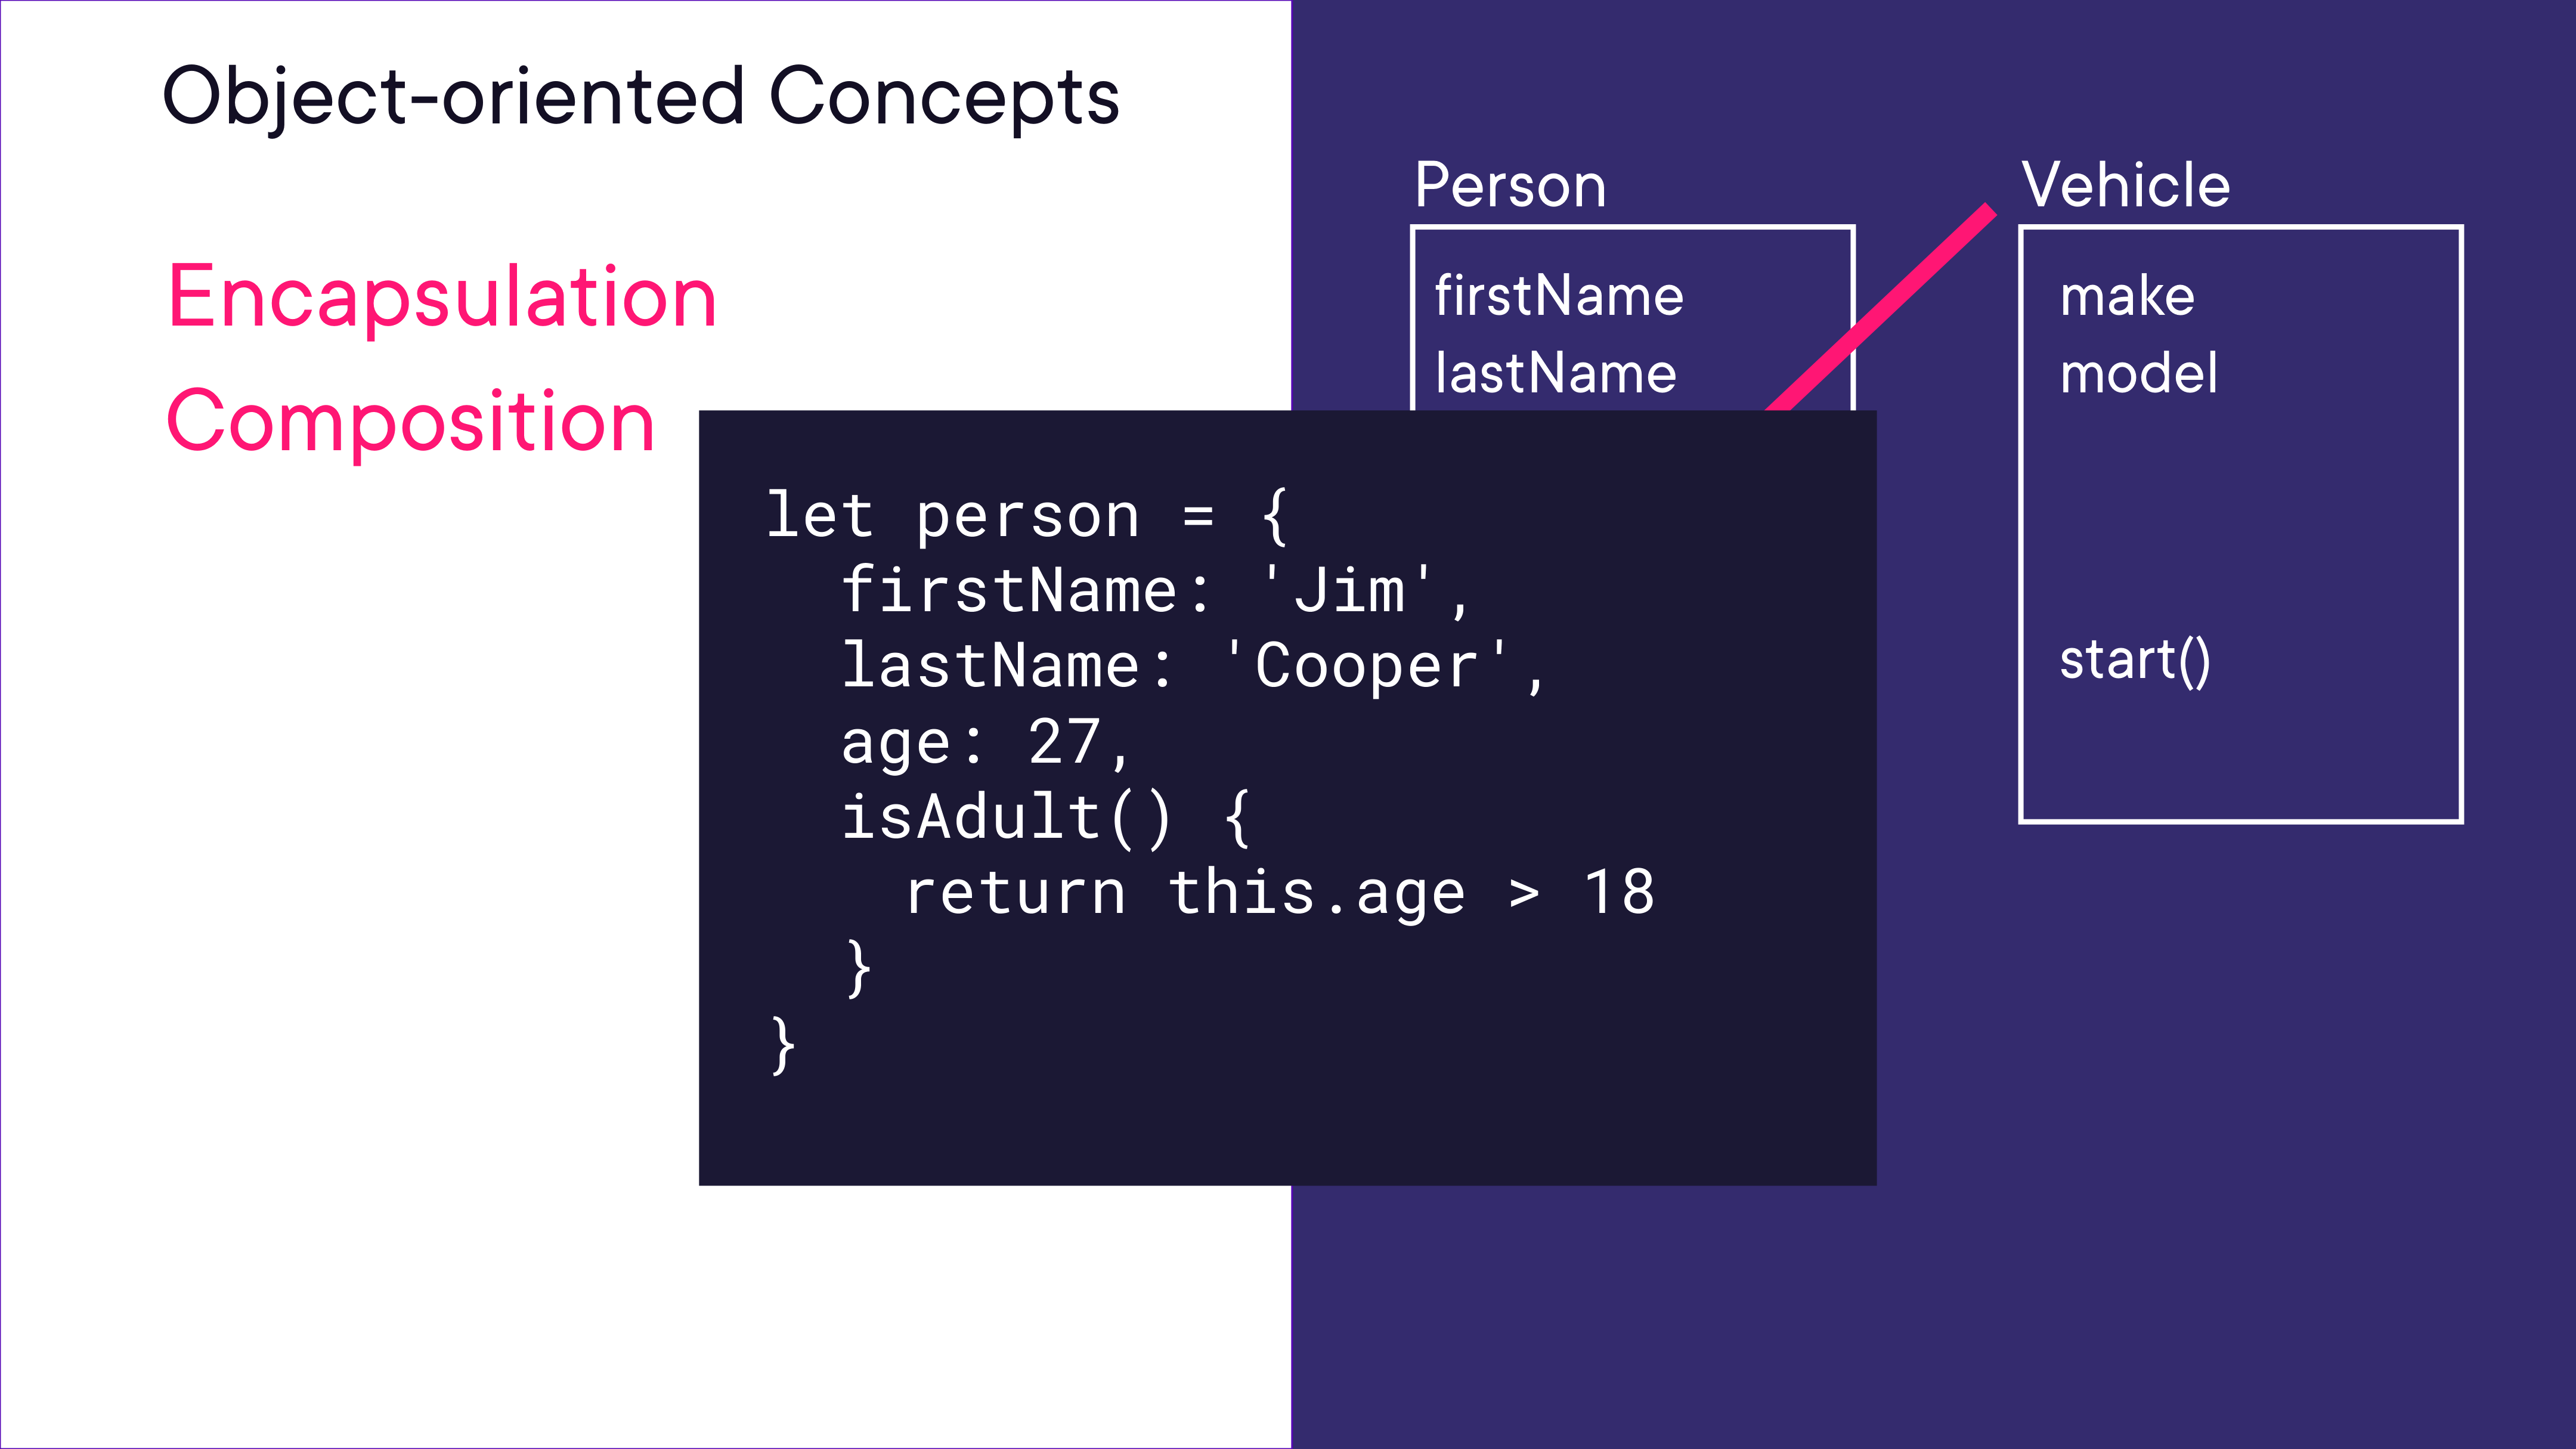

In [2]:
render_diagram(Path("assets/01-encapsulation-composition.png"))

```javascript
// Encapsulation: data and behaviour in one object
let person = {
  firstName: 'Jim',
  lastName: 'Cooper',
  age: 27,
  isAdult() {
    return this.age > 18;
  }
};

// Composition: person contains a reference to vehicles
// person.vehicles = [ vehicle1, vehicle2 ];
```

#### Inheritance

A `Student` can inherit `firstName`, `lastName`, `age`, and `isAdult()` from `Person`, and add its own properties and methods on top.


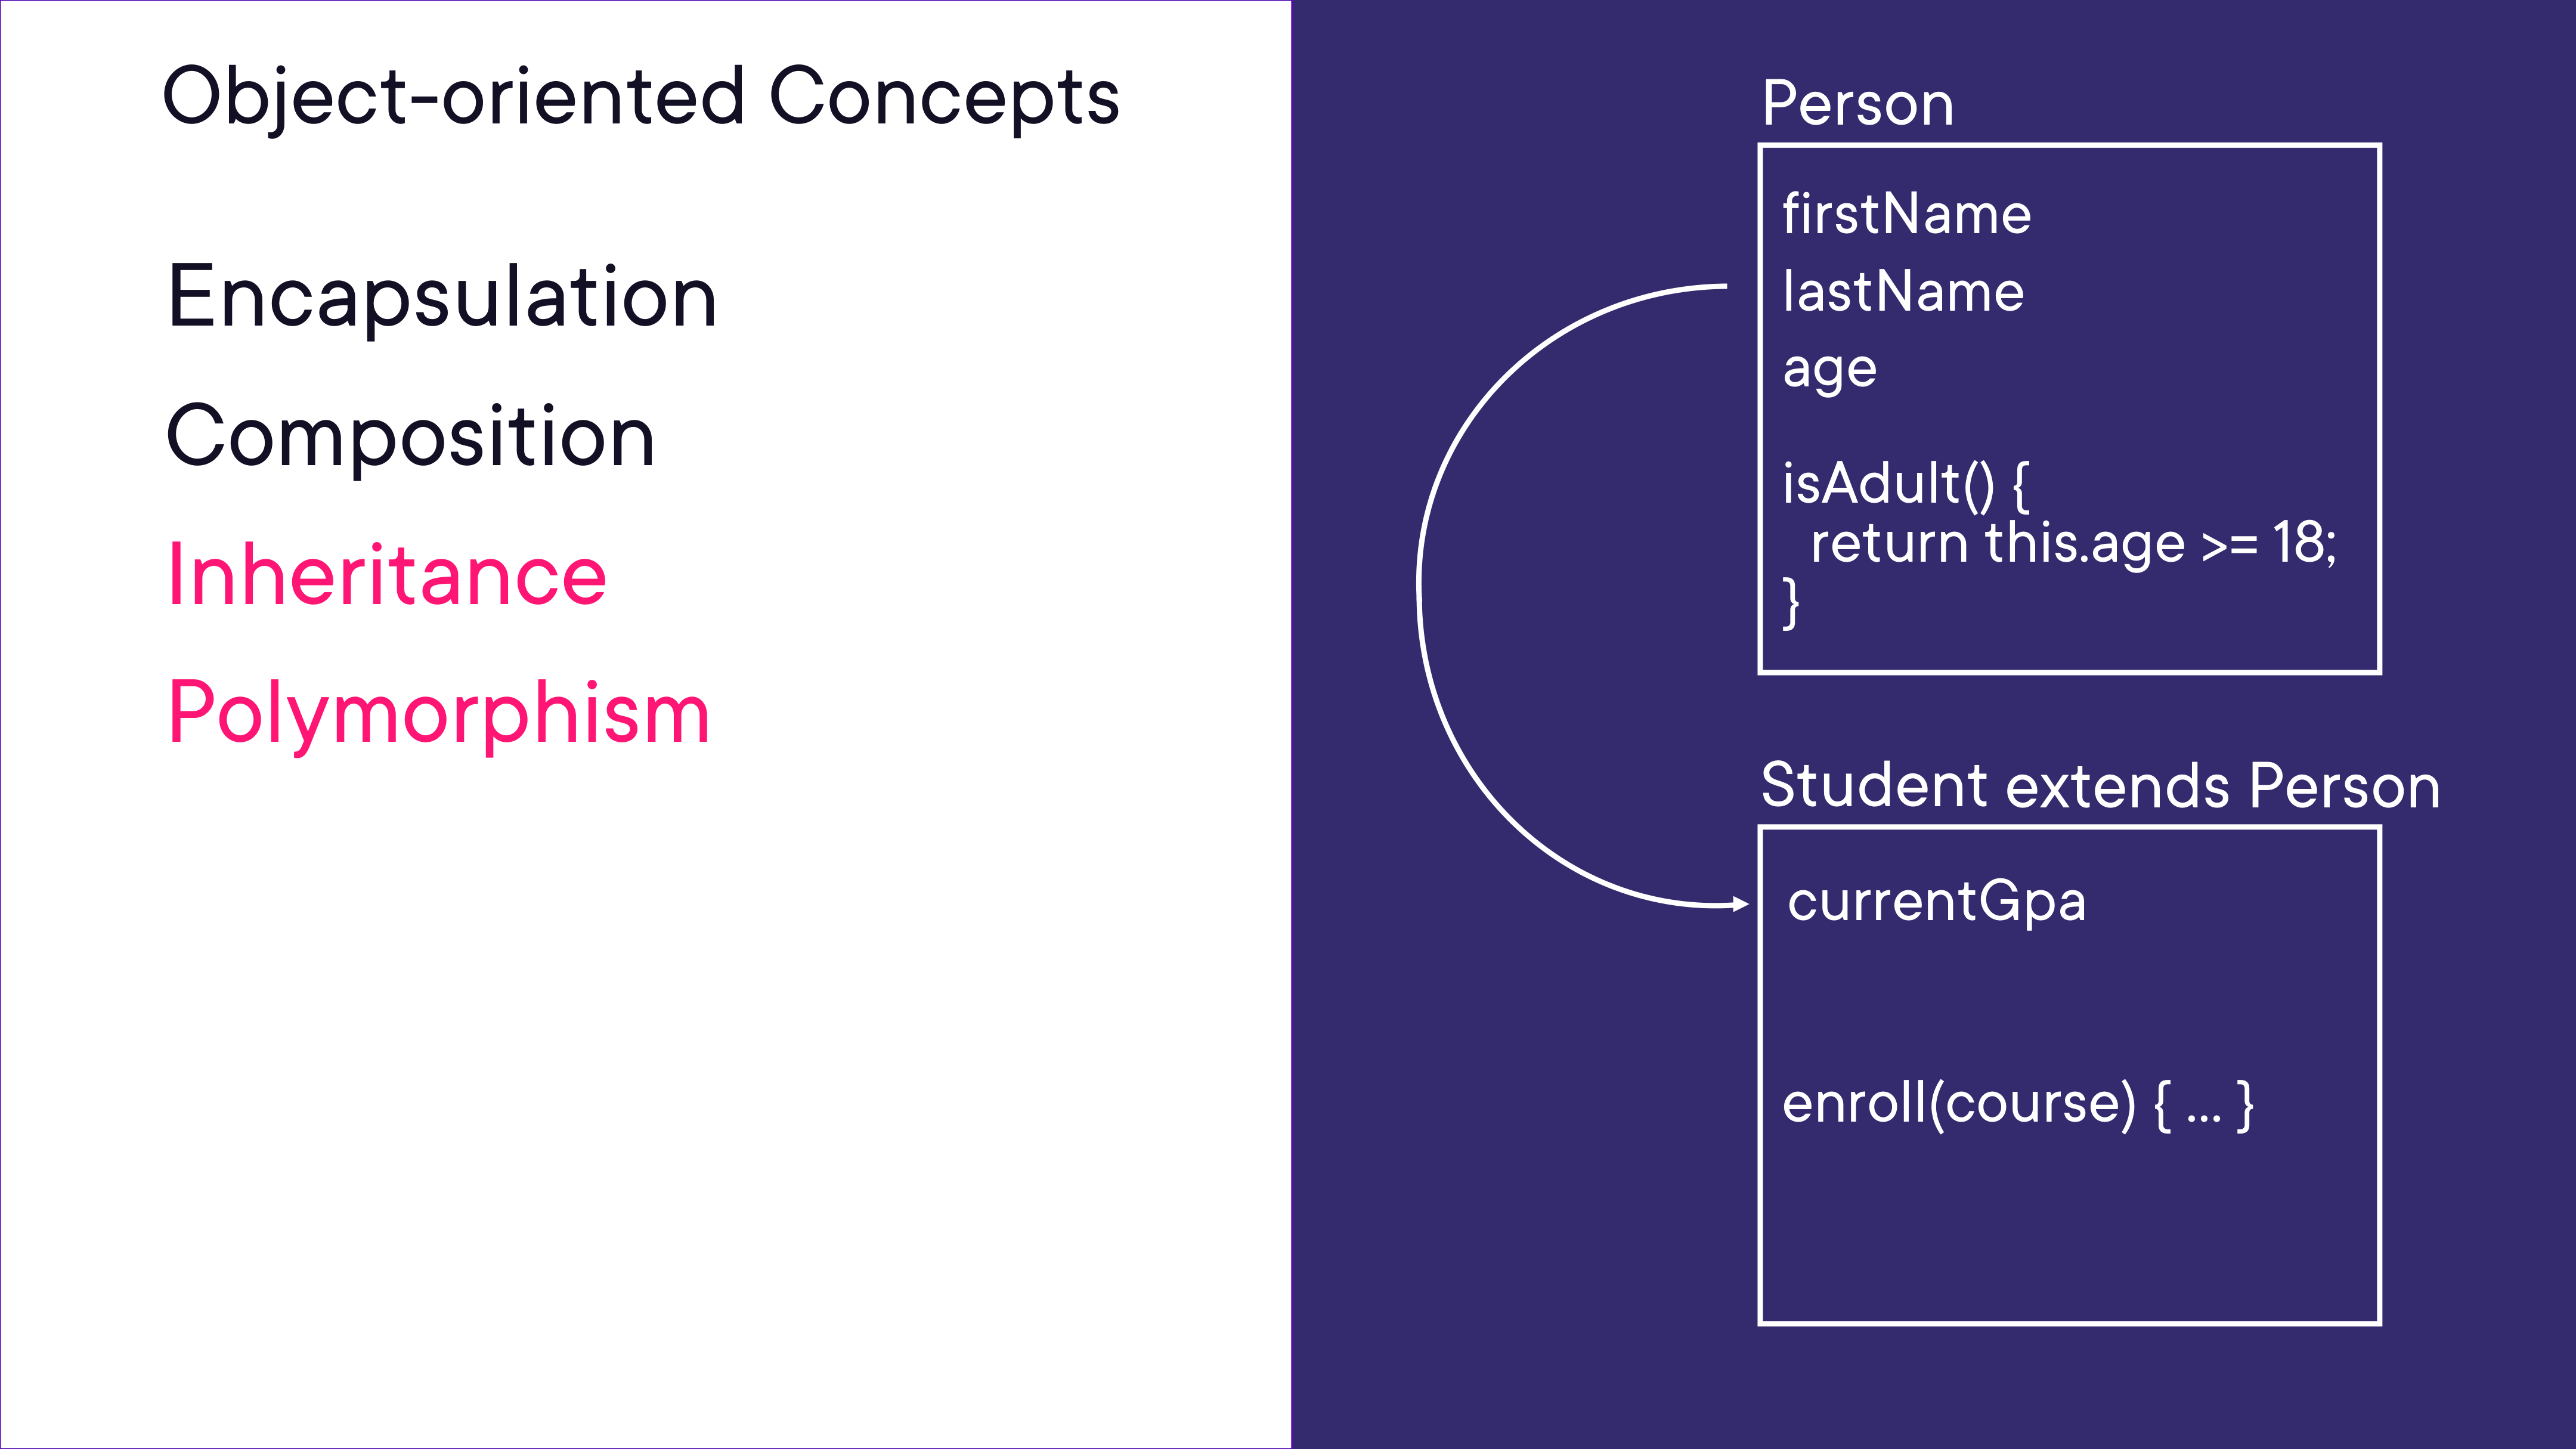

In [3]:
render_diagram(Path("assets/02-oo-concepts-inheritance.png"))

#### Polymorphism

Polymorphism means a function written against a base type (e.g. `Person`) works equally when passed a derived type (e.g. `Student`) — as long as it exposes the same interface. A derived type can also **override** a method with specialised behaviour.


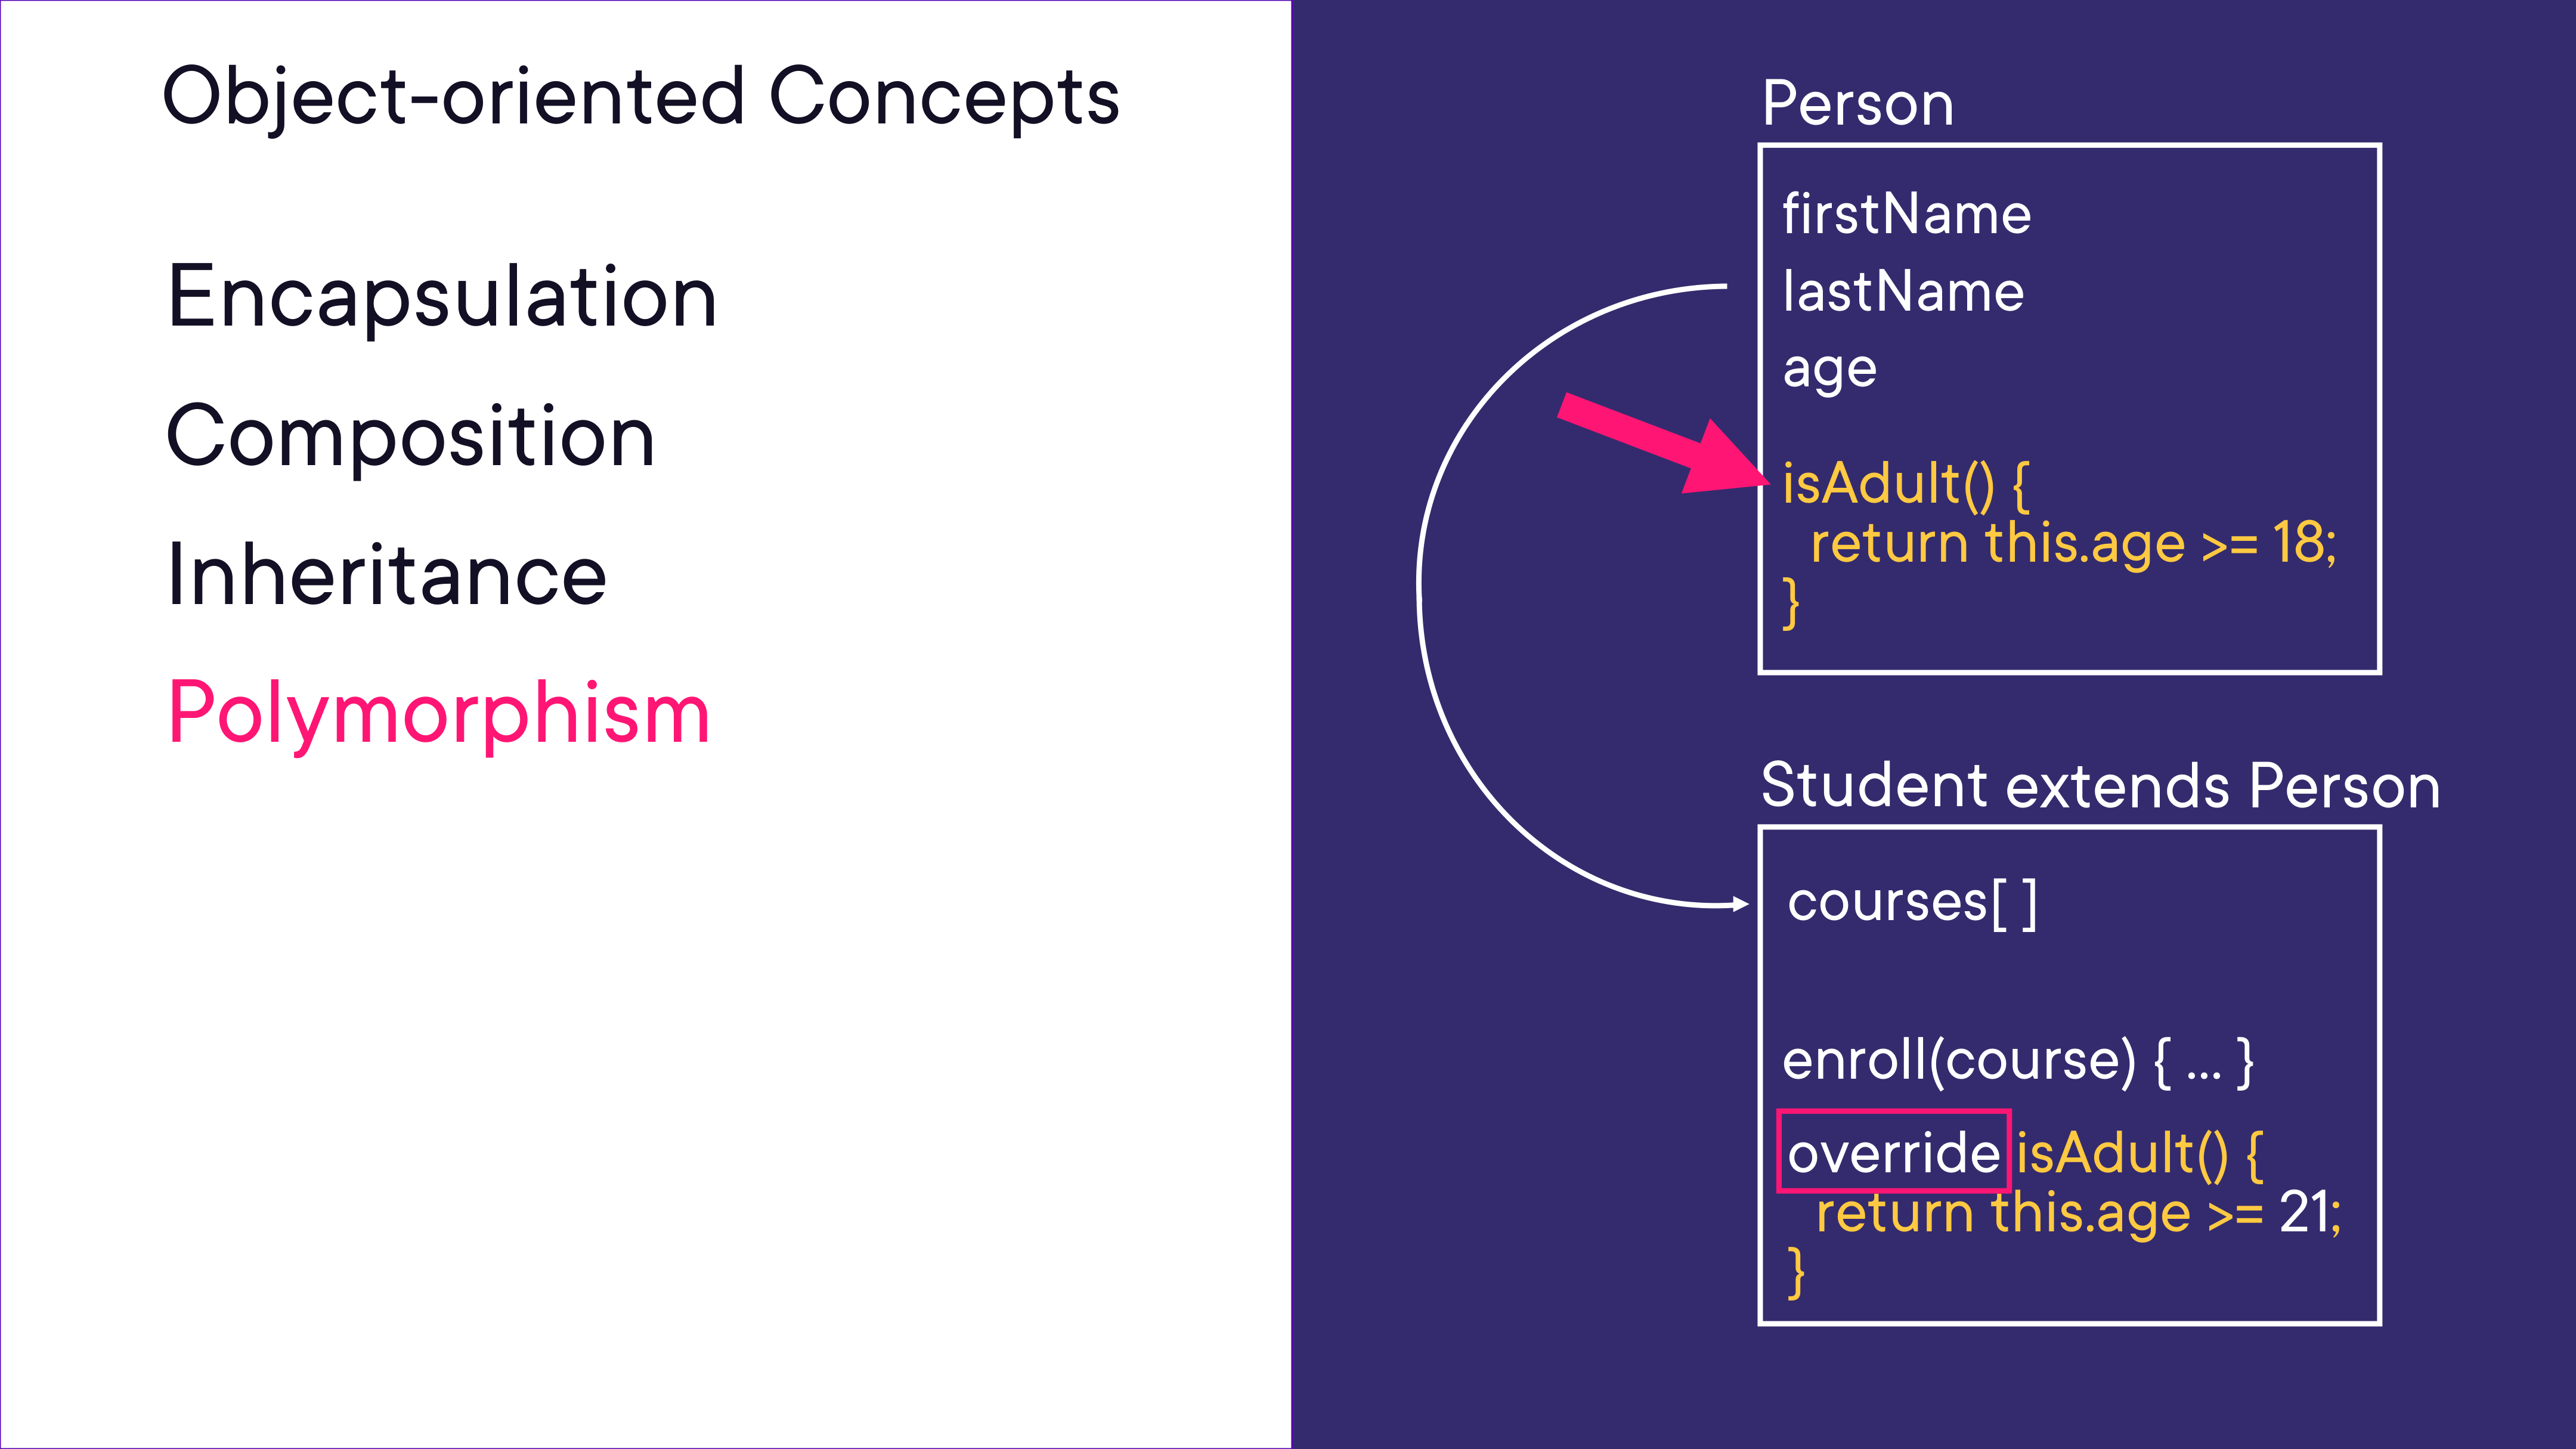

In [4]:
render_diagram(Path("assets/03-oo-concepts-polymorphism.png"))

```javascript
// Polymorphism: getFullName accepts any object with firstName/lastName
function getFullName(person) {
  return person.firstName + ' ' + person.lastName;
}

// Works with a plain Person or a Student
getFullName(myStudent);

// Method override: Student has its own isAdult() threshold
// Person.isAdult()  → age >= 18
// Student.isAdult() → age >= 21  (override)
```

### JavaScript is Loosely-typed and Prototype-based

JavaScript differs from traditional OO languages in two important ways:

**Loosely typed** — variables have no declared type. The same variable can hold a number, then a string. Functions accept any argument without a type annotation, so polymorphism works structurally rather than through explicit interface declarations.

| Traditional (strongly typed) | JavaScript (loosely typed) |
|---|---|
| `int age = 5;` | `let age = 5;` |
| `age = 'five'; // compile error` | `age = 'five'; // fine` |
| `function getFullName(Person person) {...}` | `function getFullName(person) {...}` |
| `Person jim = new Person();` | `let jim = new Person();` |

**Prototype-based** — instead of class blueprints, JavaScript uses a **prototype chain**: each object has a hidden `__proto__` link to another object (its prototype) from which it inherits properties and methods. ES6 `class` syntax is built on top of this prototype mechanism.


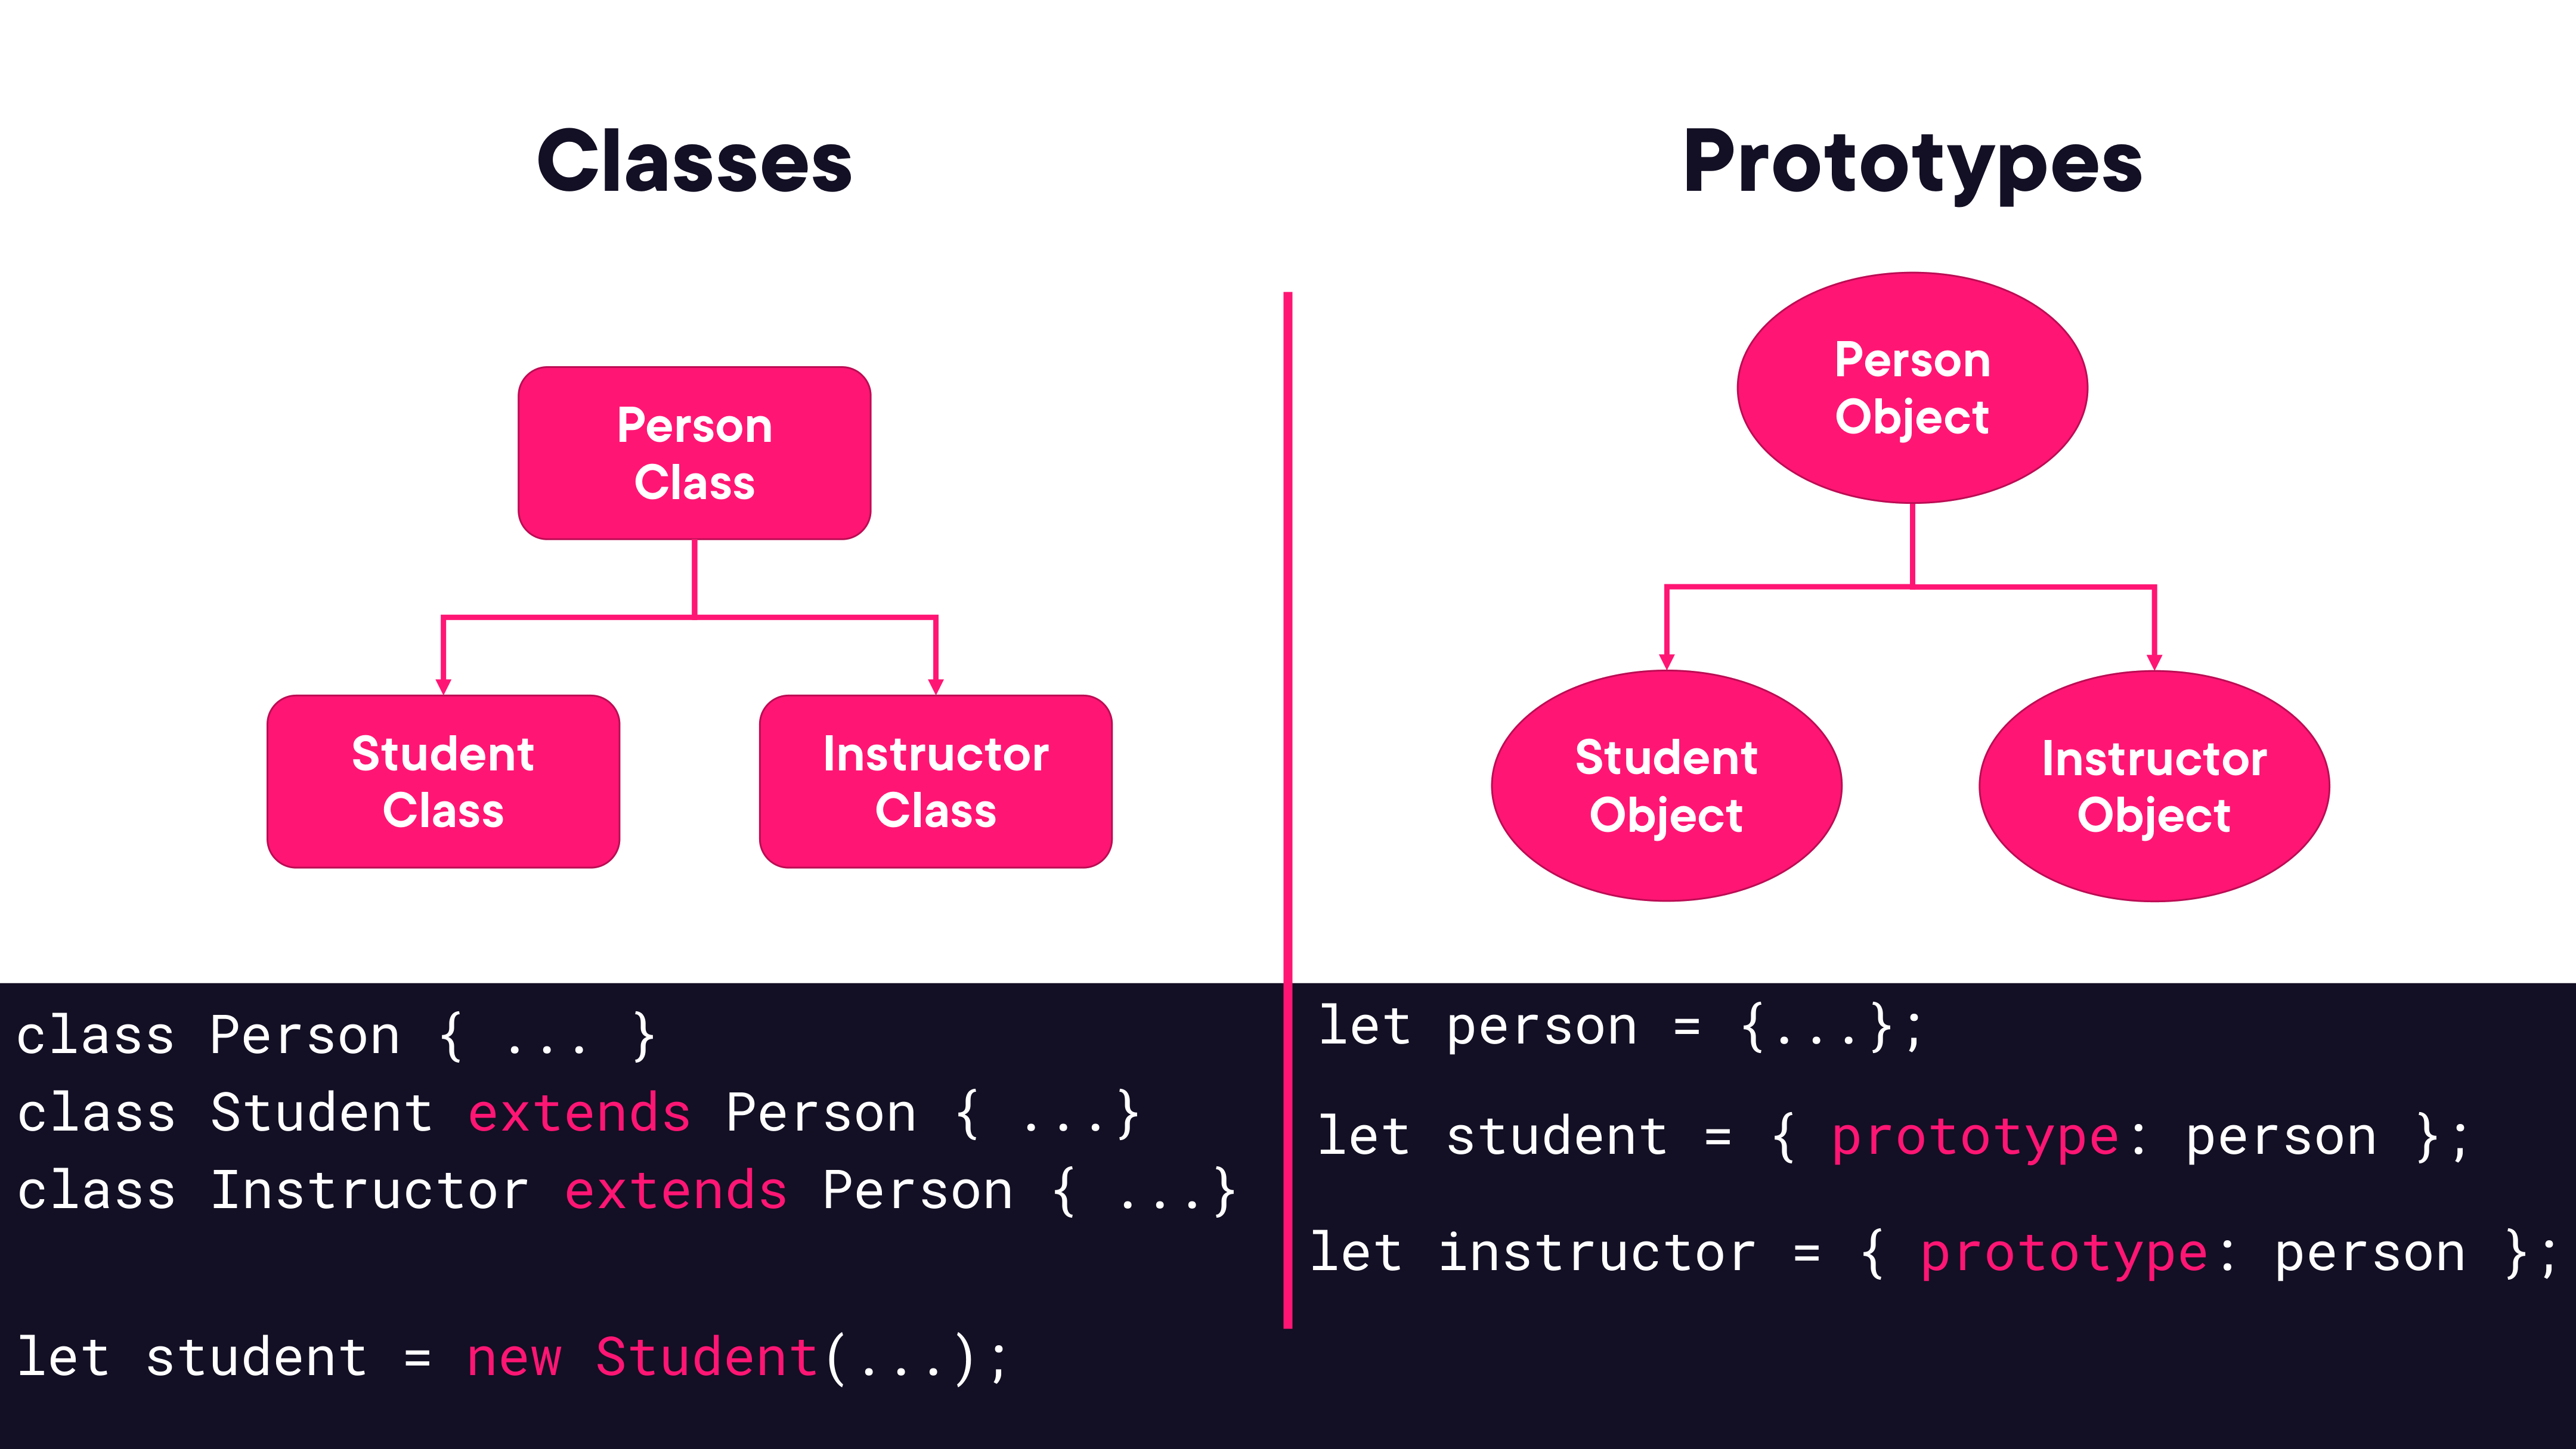

In [5]:
render_diagram(Path("assets/04-prototypes-vs-classes.png"))

## Module 02: Understanding JavaScript Prototypes <a id="module-02"></a>

_Explores how JavaScript's prototype chain works at the object level — setting prototypes directly with `Object.setPrototypeOf()`, following the chain for property lookup, and how `Object` sits at the top of every chain._

### The Prototype Chain

Every JavaScript object has an internal `__proto__` property pointing to another object — its **prototype**. When you access a property, JavaScript first looks on the object itself, then walks up the `__proto__` chain until it finds it or reaches `null`.

`Object.setPrototypeOf(child, parent)` establishes this link explicitly.


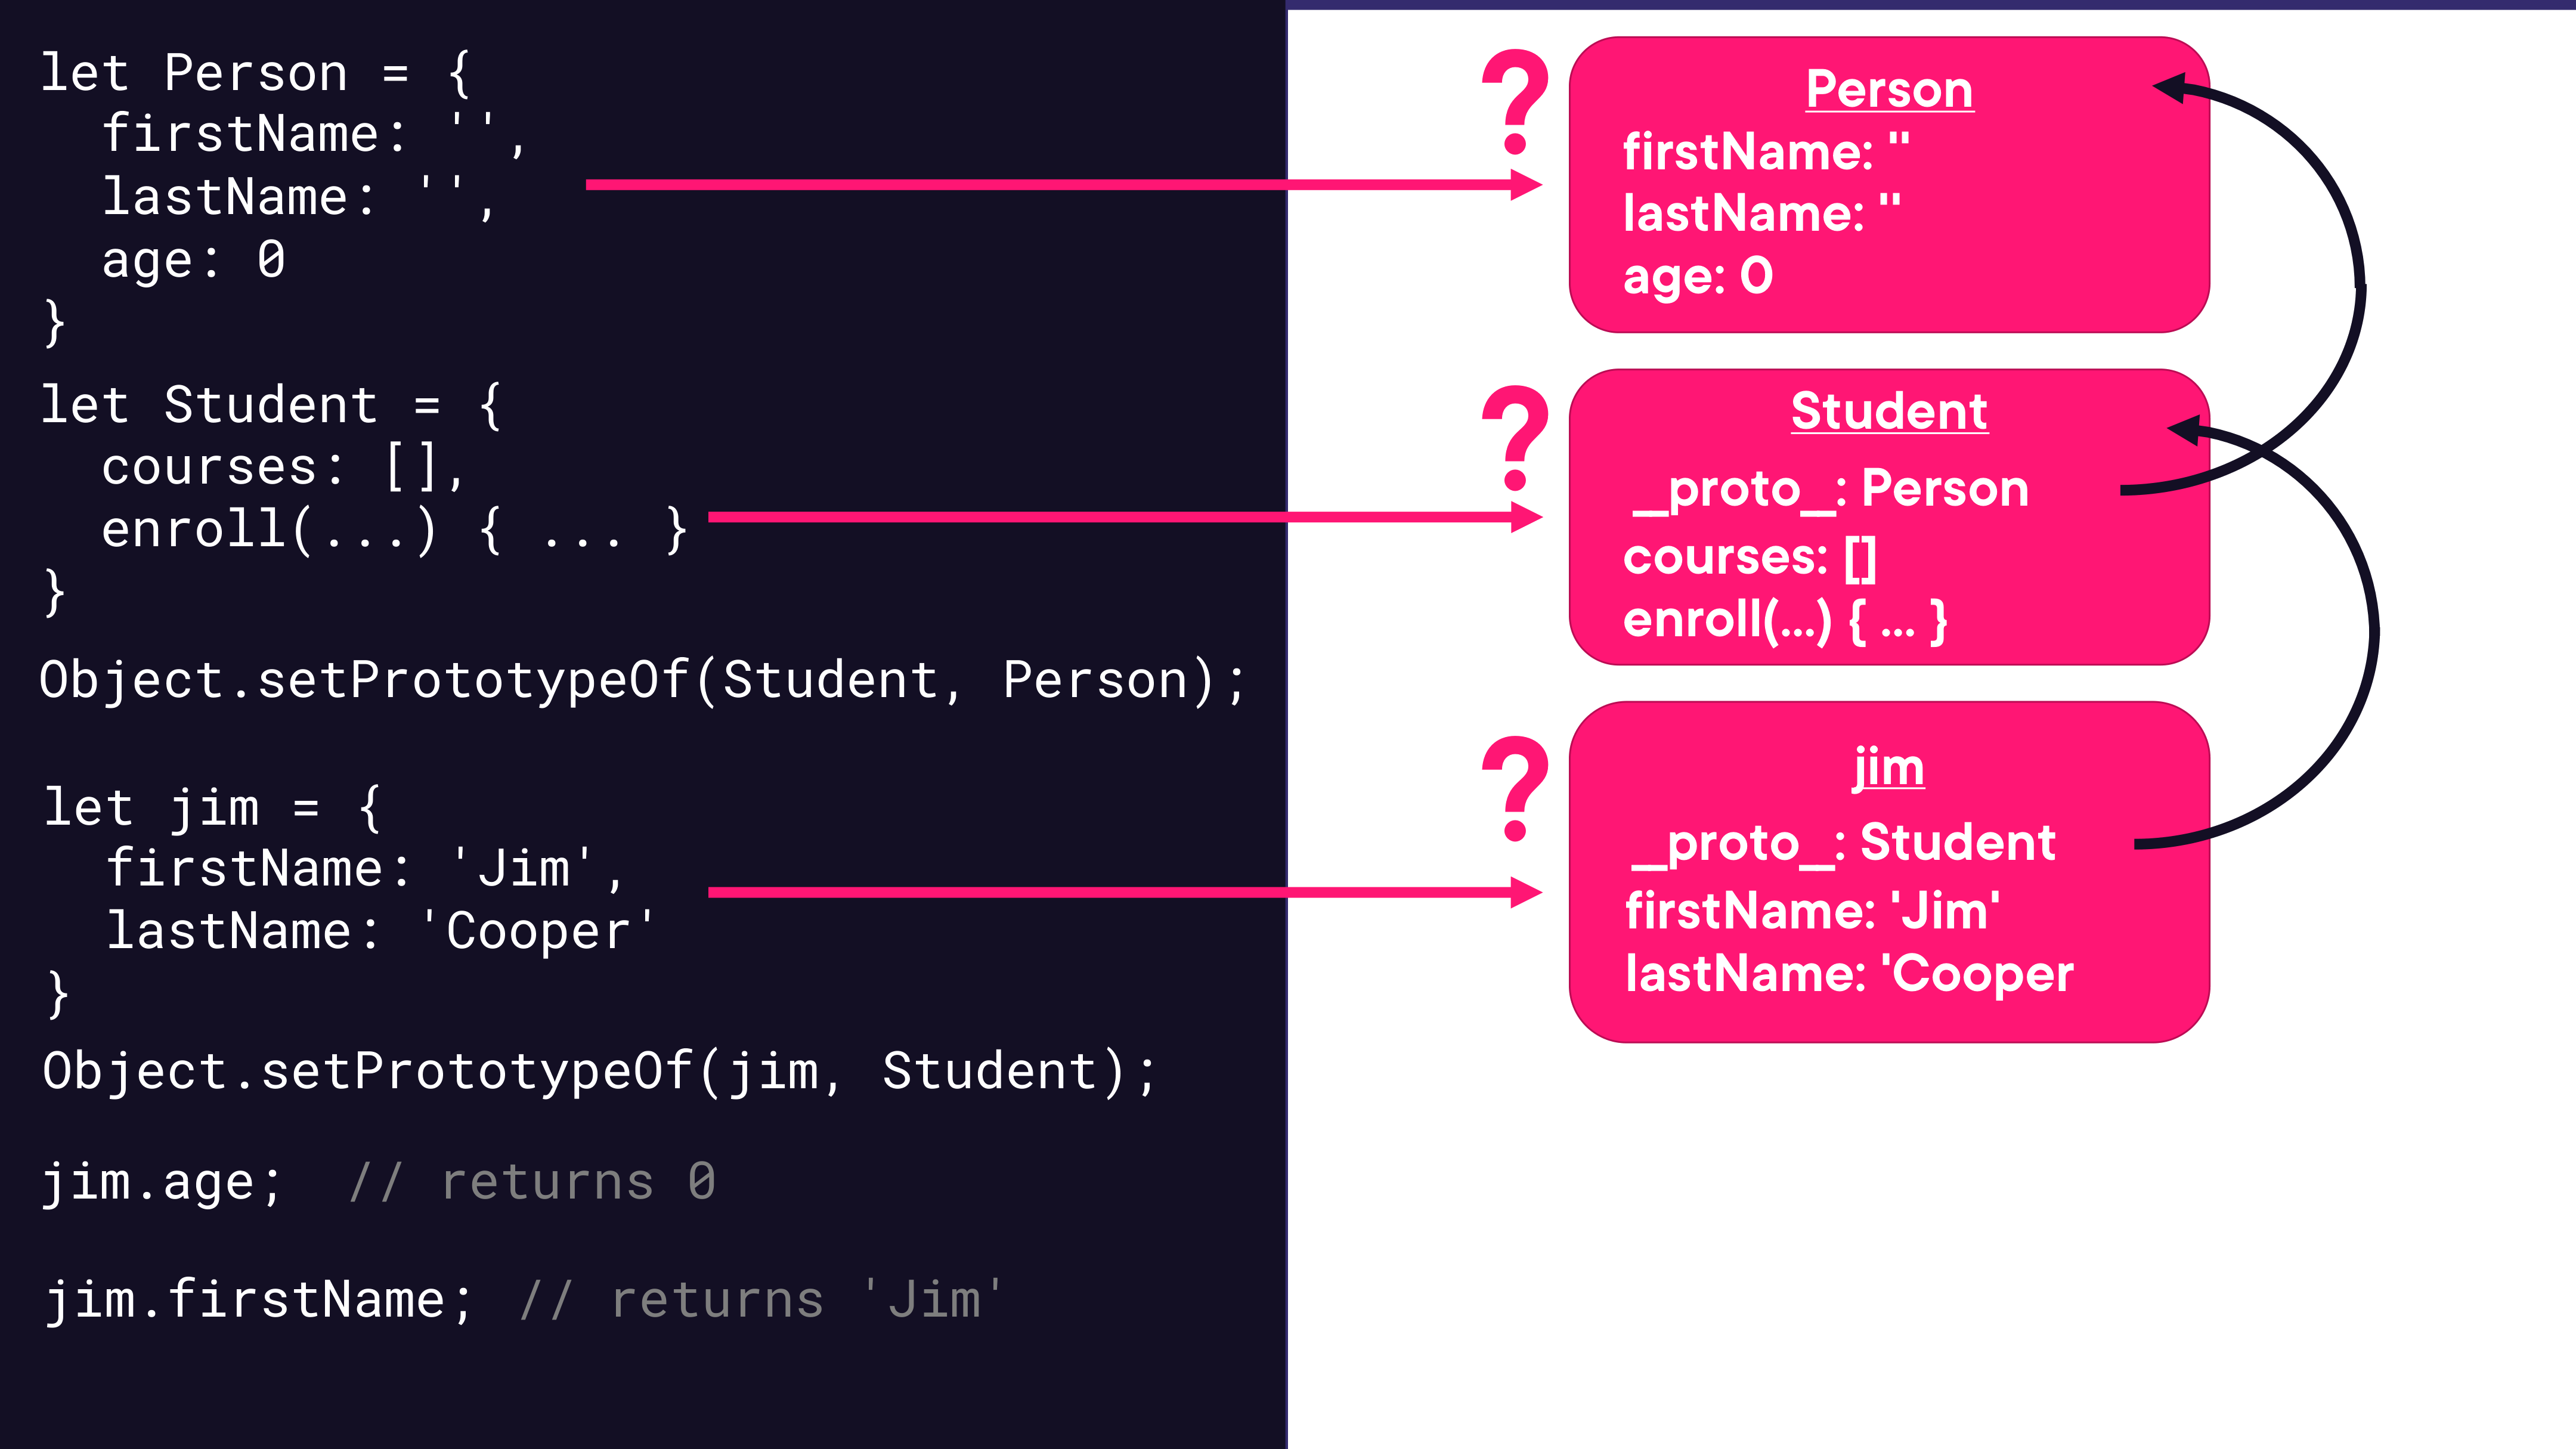

In [6]:
render_diagram(Path("assets/05-prototype-chain.png"))

```javascript
let Person = {
  firstName: '',
  lastName: '',
  age: 0,
  fullName() {
    return `${this.firstName} ${this.lastName}`;
  },
};

let Student = {
  courses: [],
  enroll(course) {
    this.courses.push(course);
  },
};
Object.setPrototypeOf(Student, Person);  // Student.__proto__ = Person

let jim = { firstName: 'Jim', lastName: 'Cooper' };
Object.setPrototypeOf(jim, Student);     // jim.__proto__ = Student

jim.age;       // 0      — found on Person via chain
jim.firstName; // 'Jim'  — found on jim itself
```

Property lookup order for `jim.age`:
1. Check `jim` — not found
2. Check `jim.__proto__` (Student) — not found
3. Check `Student.__proto__` (Person) — **found: `age: 0`**

### Object at the Top of Every Chain

Every prototype chain ultimately ends at the built-in `Object` prototype, which provides methods like `hasOwnProperty()` that are available on all objects. `hasOwnProperty()` returns `true` only if the property exists directly on the object, not inherited through the chain.


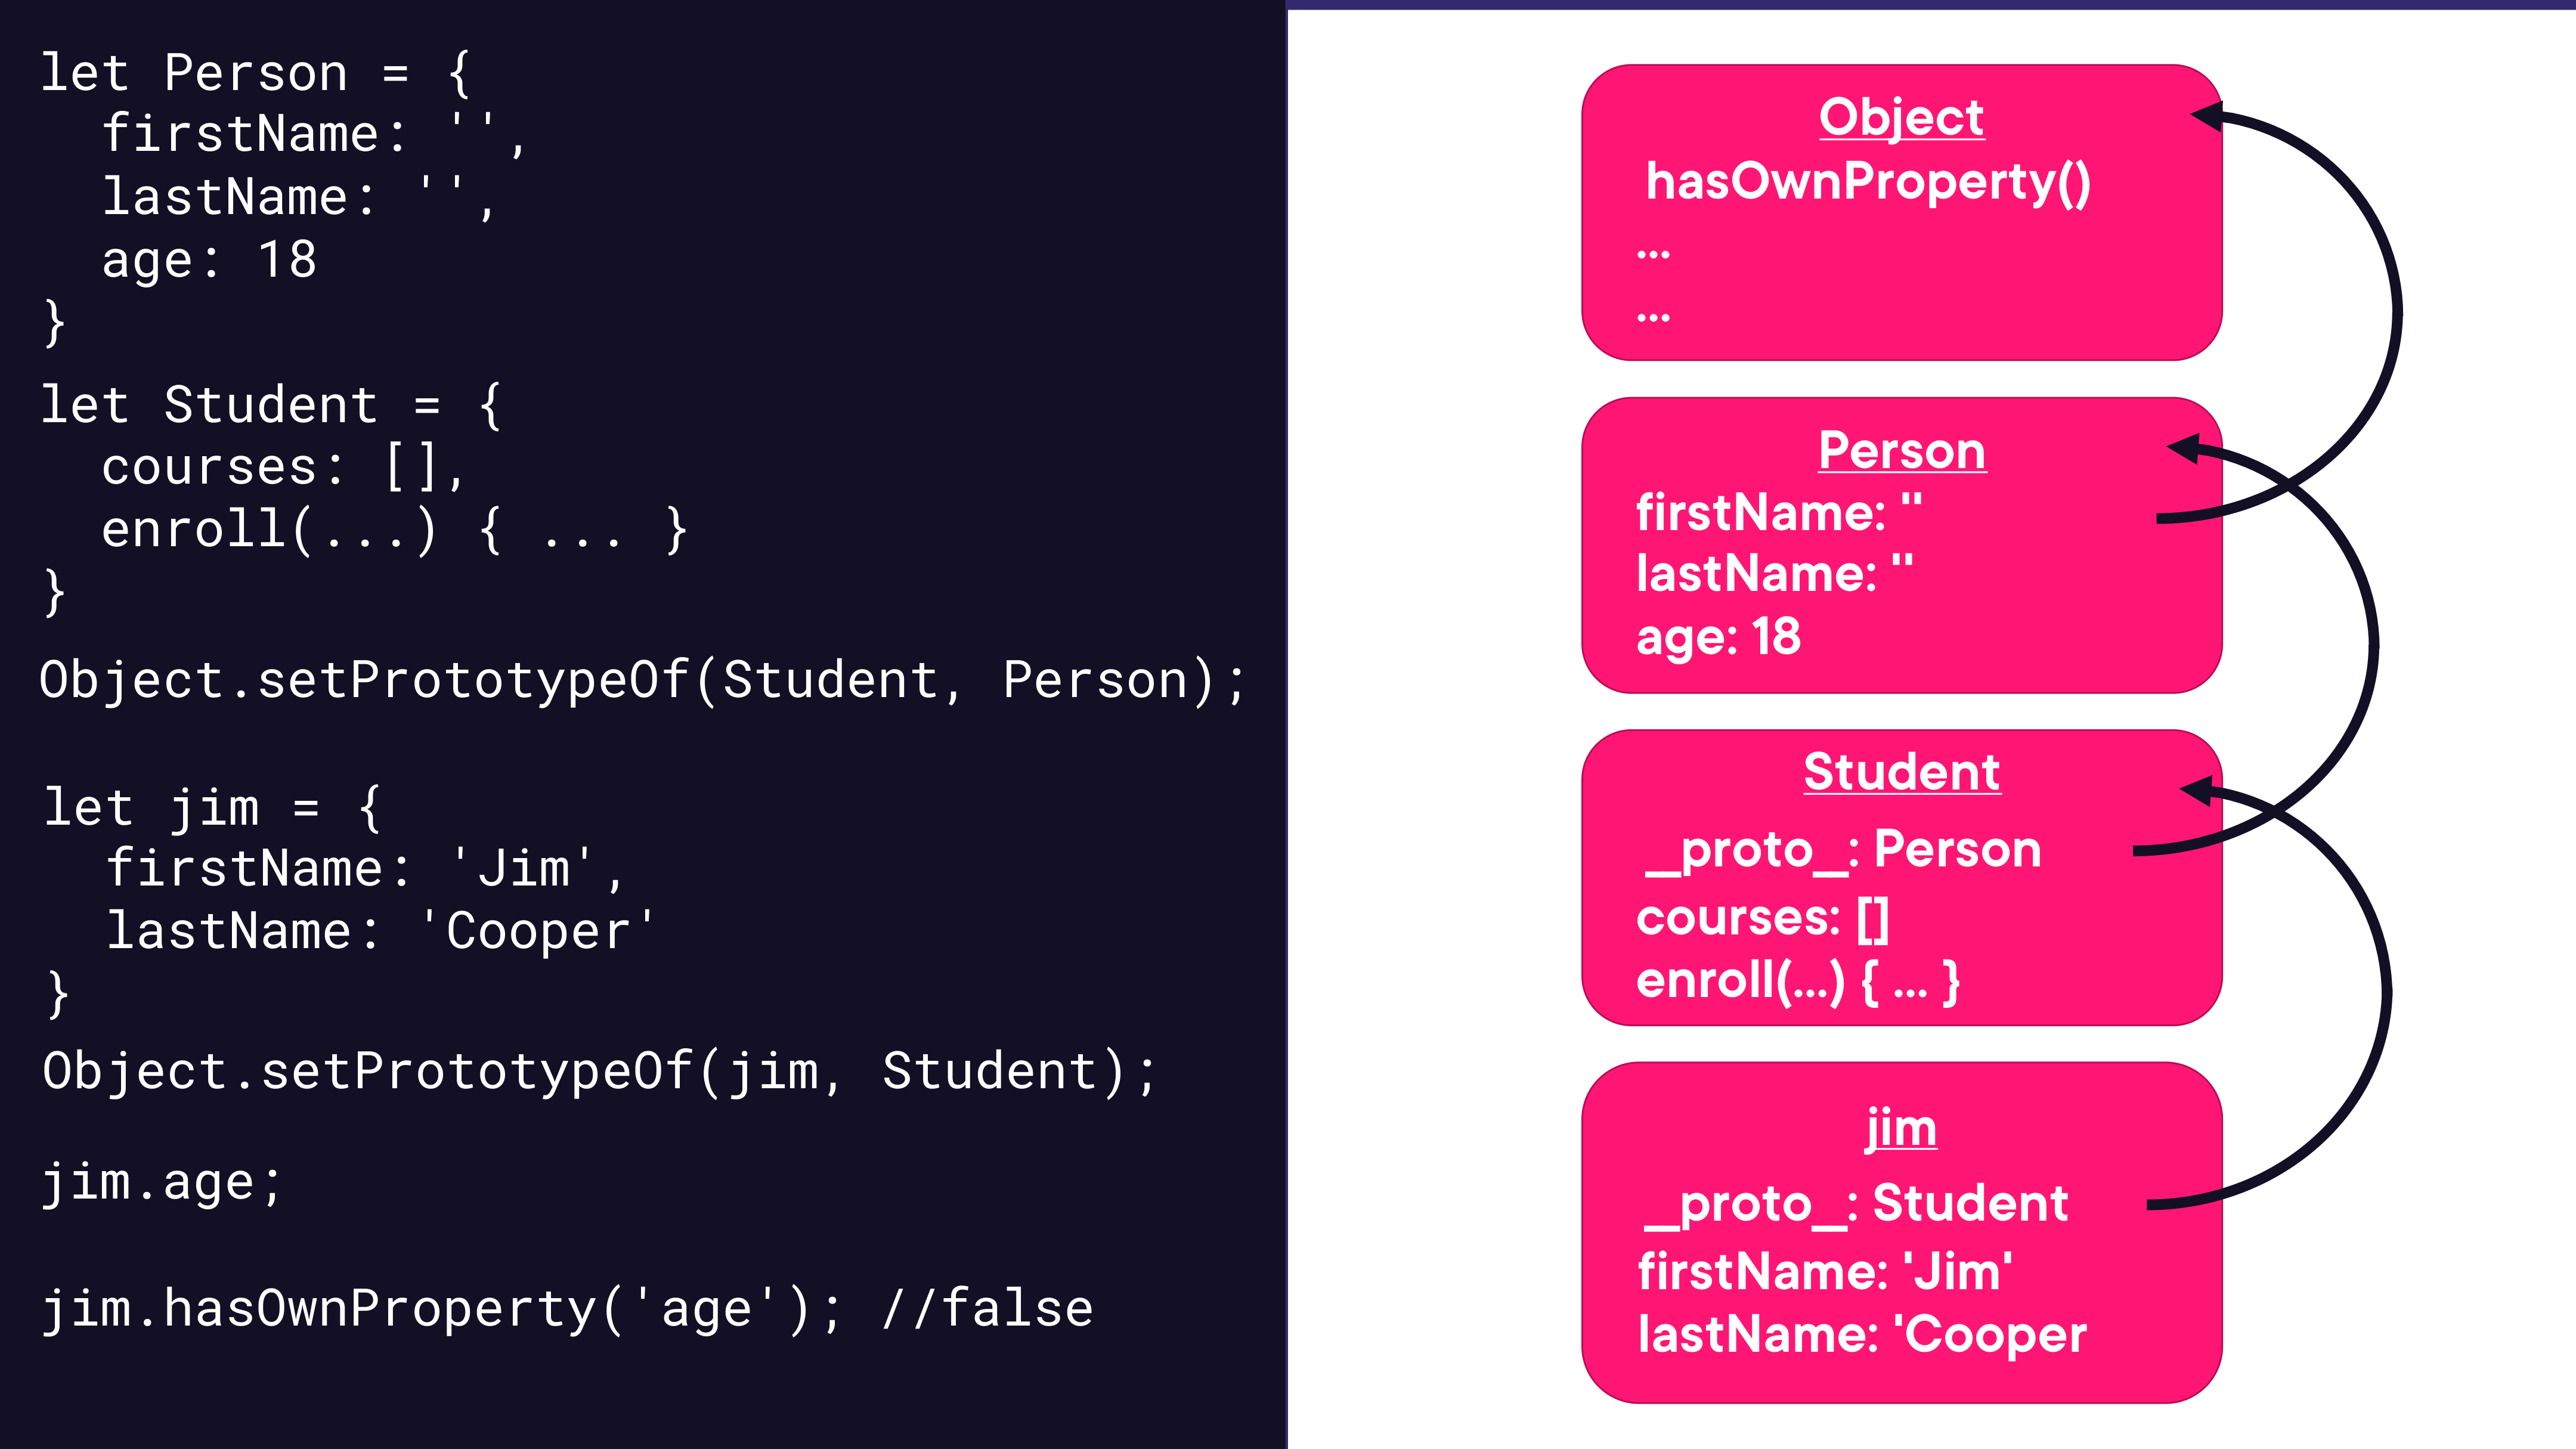

In [7]:
render_diagram(Path("assets/06-prototype-chain-object.png"))

```javascript
jim.hasOwnProperty('age');       // false — age is on Person, not jim
jim.hasOwnProperty('firstName'); // true  — firstName is on jim itself
```

Full chain for `jim`: `jim` → `Student` → `Person` → `Object` → `null`

### Demo: Prototypes

**Working prototype chain with `Object.setPrototypeOf()`.**

See [`01-introduction-demos/`](01-introduction-demos/) for the starter and finished versions.

The demo uses a `display()` helper function (provided in `helper/_helper.js`) to print output in the browser. The `before/script.js` is empty — the `after/script.js` shows the completed working example:

```javascript
// 02-prototypes-demos/after/script.js
let Person = {
  firstName: '',
  lastName: '',
  age: 21,
  fullName() {
    return `${this.firstName} ${this.lastName}`;
  },
};

let Student = {
  enrolledCourses: [],
  enroll(course) {
    this.enrolledCourses.push(course);
  },
};
Object.setPrototypeOf(Student, Person);

let jim = { firstName: 'Jim', lastName: 'Cooper', age: 29 };
Object.setPrototypeOf(jim, Student);

jim.enroll({ courseId: 'CS101' });
display(jim.enrolledCourses); // [{ courseId: 'CS101' }]
display(jim.age);             // 29  (own property shadows Person.age)
display(jim.fullName());      // 'Jim Cooper'
```

## Module 03: Using JavaScript Constructor Functions <a id="module-03"></a>

_Covers constructor functions as a pattern for creating many objects with the same shape, how `new` works internally, and why methods belong on `prototype` rather than inside the constructor._

### Constructor Functions and the `new` Keyword

A **constructor function** is a regular function called with `new`. By convention, constructor function names start with a capital letter. When called with `new`, JavaScript performs four steps automatically:


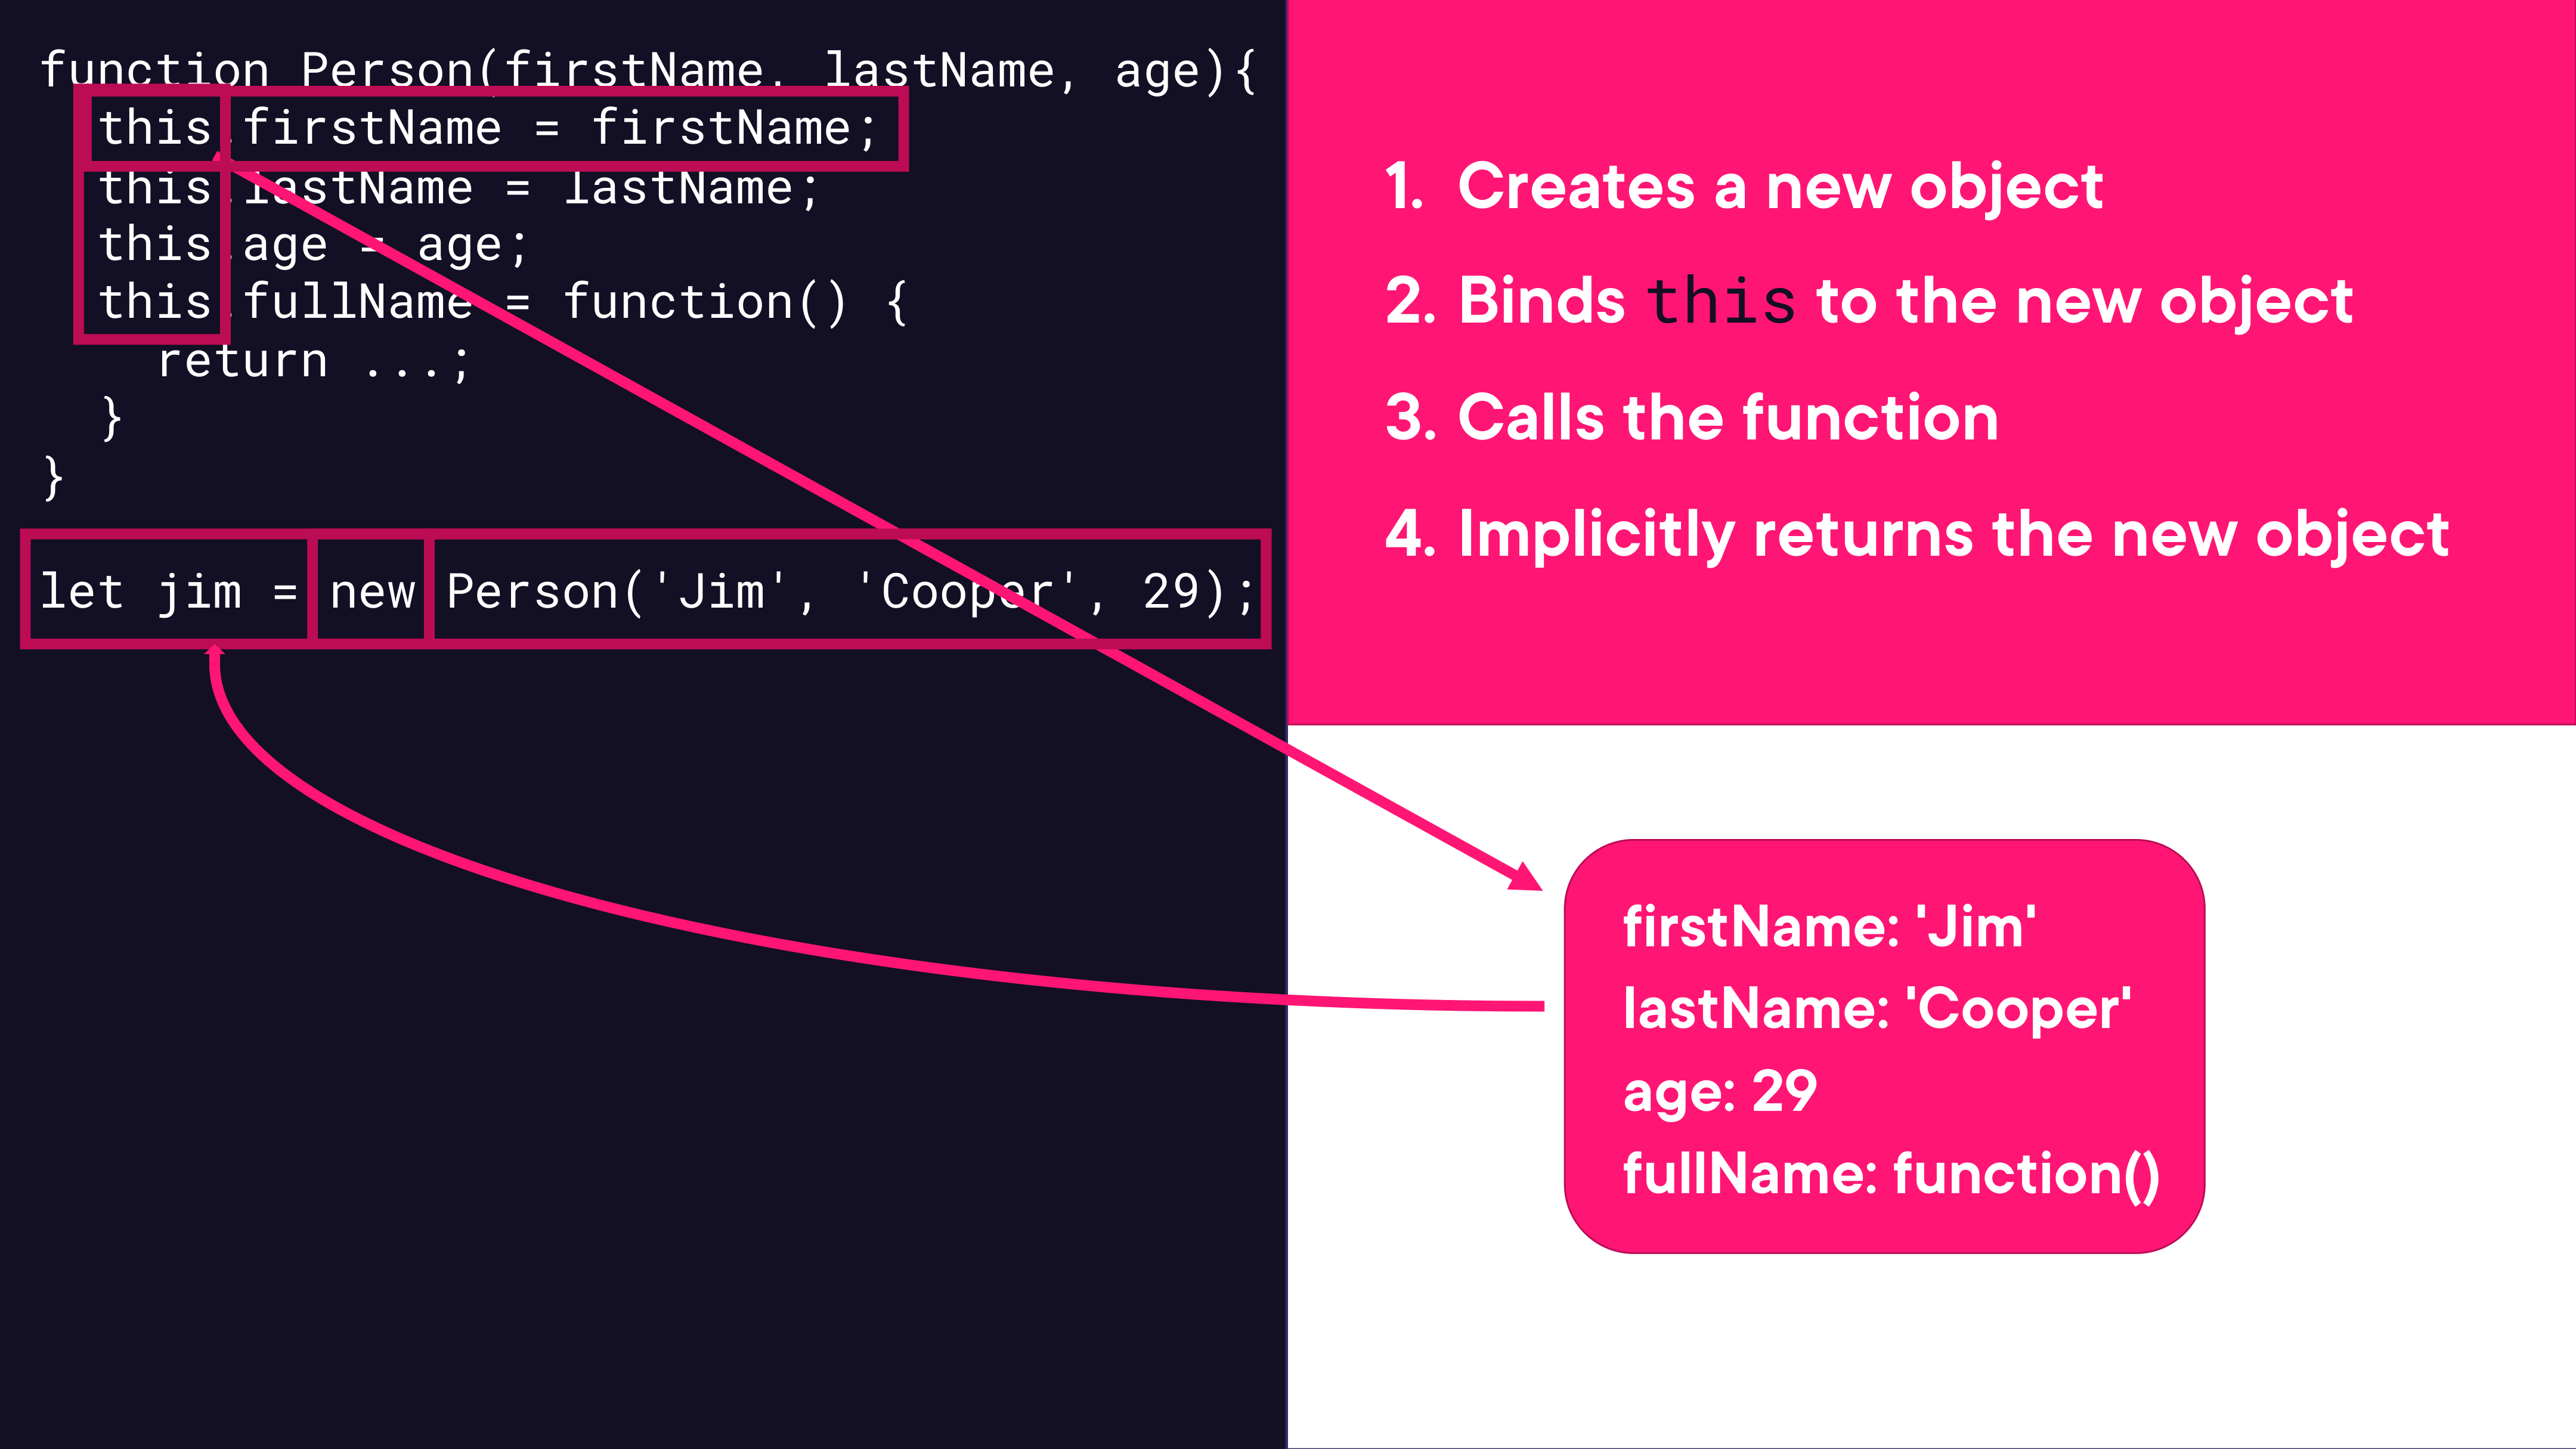

In [8]:
render_diagram(Path("assets/07-constructor-function-new.png"))

What `new` does:
1. Creates a new empty object
2. Binds `this` to that new object
3. Calls the function body (assigns properties to `this`)
4. Implicitly returns the new object

```javascript
function Person(firstName, lastName, age) {
  this.firstName = firstName;
  this.lastName  = lastName;
  this.age       = age;
  this.fullName  = function() {
    return `${this.firstName} ${this.lastName}`;
  };
}

let jim = new Person('Jim', 'Cooper', 29);
// jim = { firstName: 'Jim', lastName: 'Cooper', age: 29, fullName: fn }
```

> **Problem with methods inside the constructor:** every instance gets its own copy of `fullName`, wasting memory. The fix is to put methods on the shared prototype.

### Adding Methods to `prototype`

Every constructor function has a `prototype` property. Objects created with `new` have their `__proto__` pointed at that prototype, so all instances share the same method without duplication.


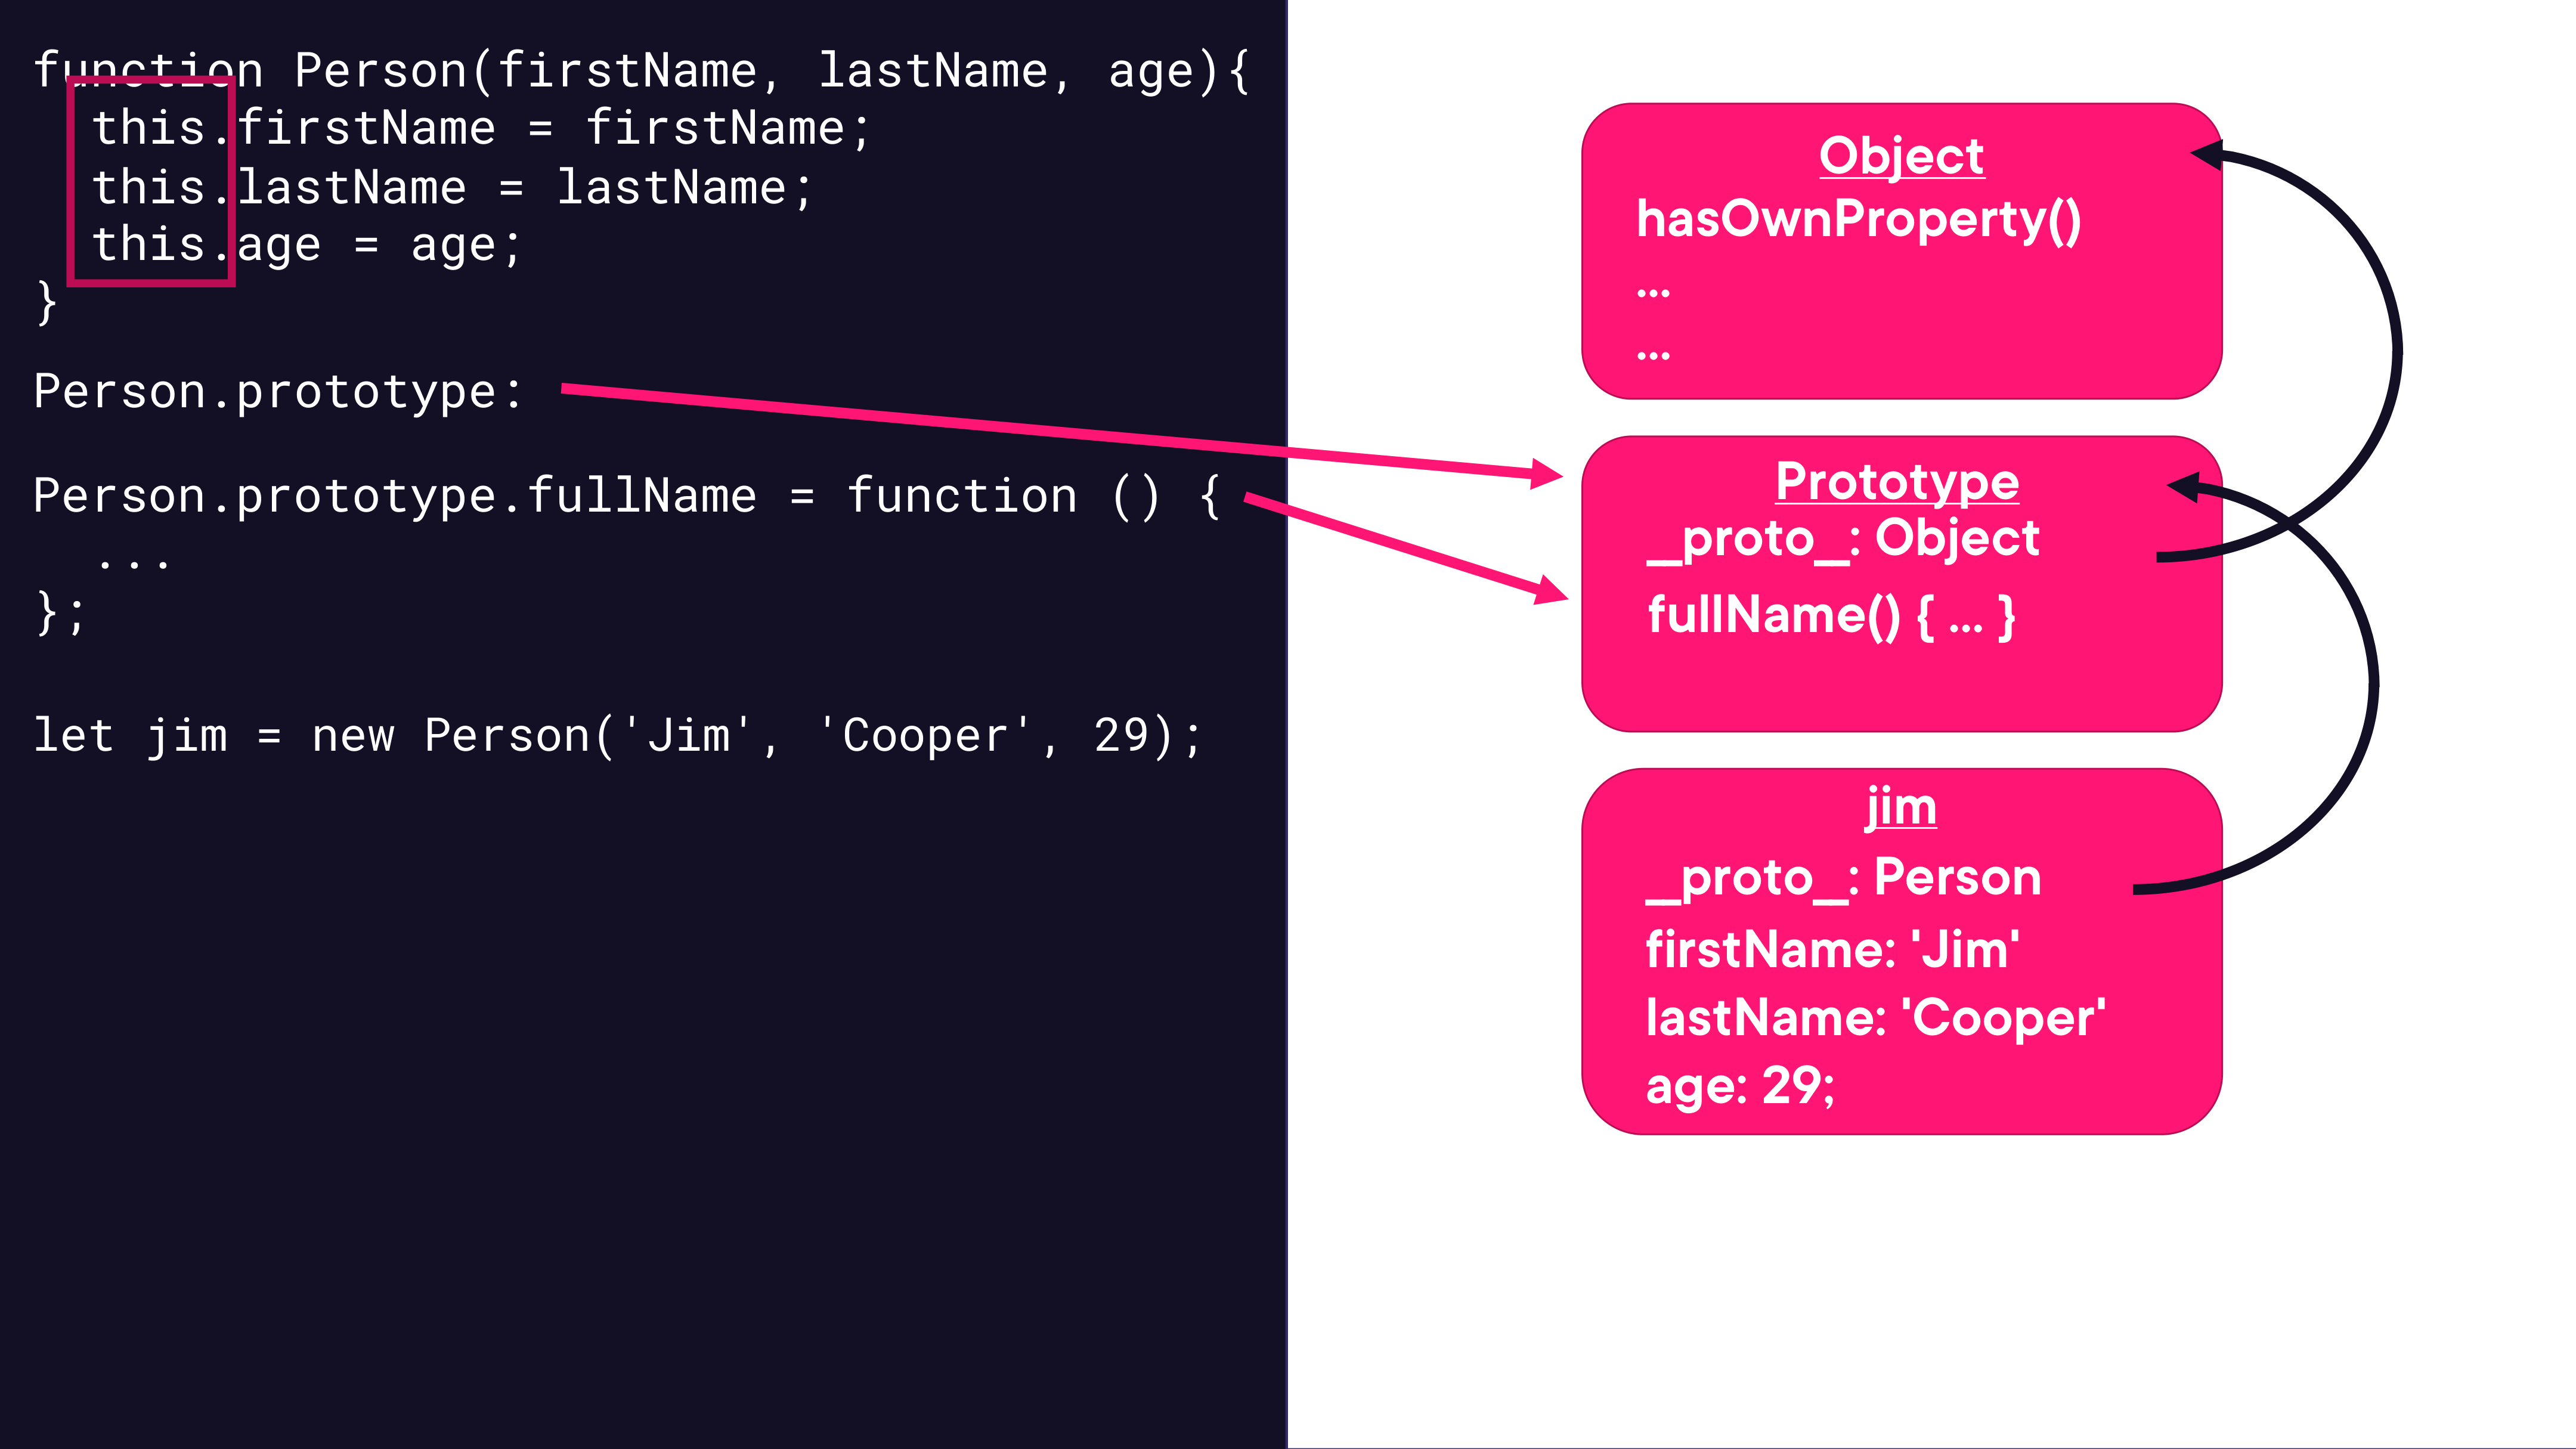

In [9]:
render_diagram(Path("assets/08-prototype-on-instance.png"))

```javascript
function Person(firstName, lastName, age) {
  this.firstName = firstName;
  this.lastName  = lastName;
  this.age       = age;
}

// Shared method — defined once on the prototype, not per-instance
Person.prototype.fullName = function() {
  return `${this.firstName} ${this.lastName}`;
};

let jim  = new Person('Jim',  'Cooper', 29);
let kris = new Person('Kris', 'Cooper', 30);

// Both instances share the same fullName function via __proto__
jim.fullName  === kris.fullName; // true — same function reference
```

The chain is: `jim` → `Person.prototype` (has `fullName`) → `Object.prototype` (has `hasOwnProperty`, etc.) → `null`


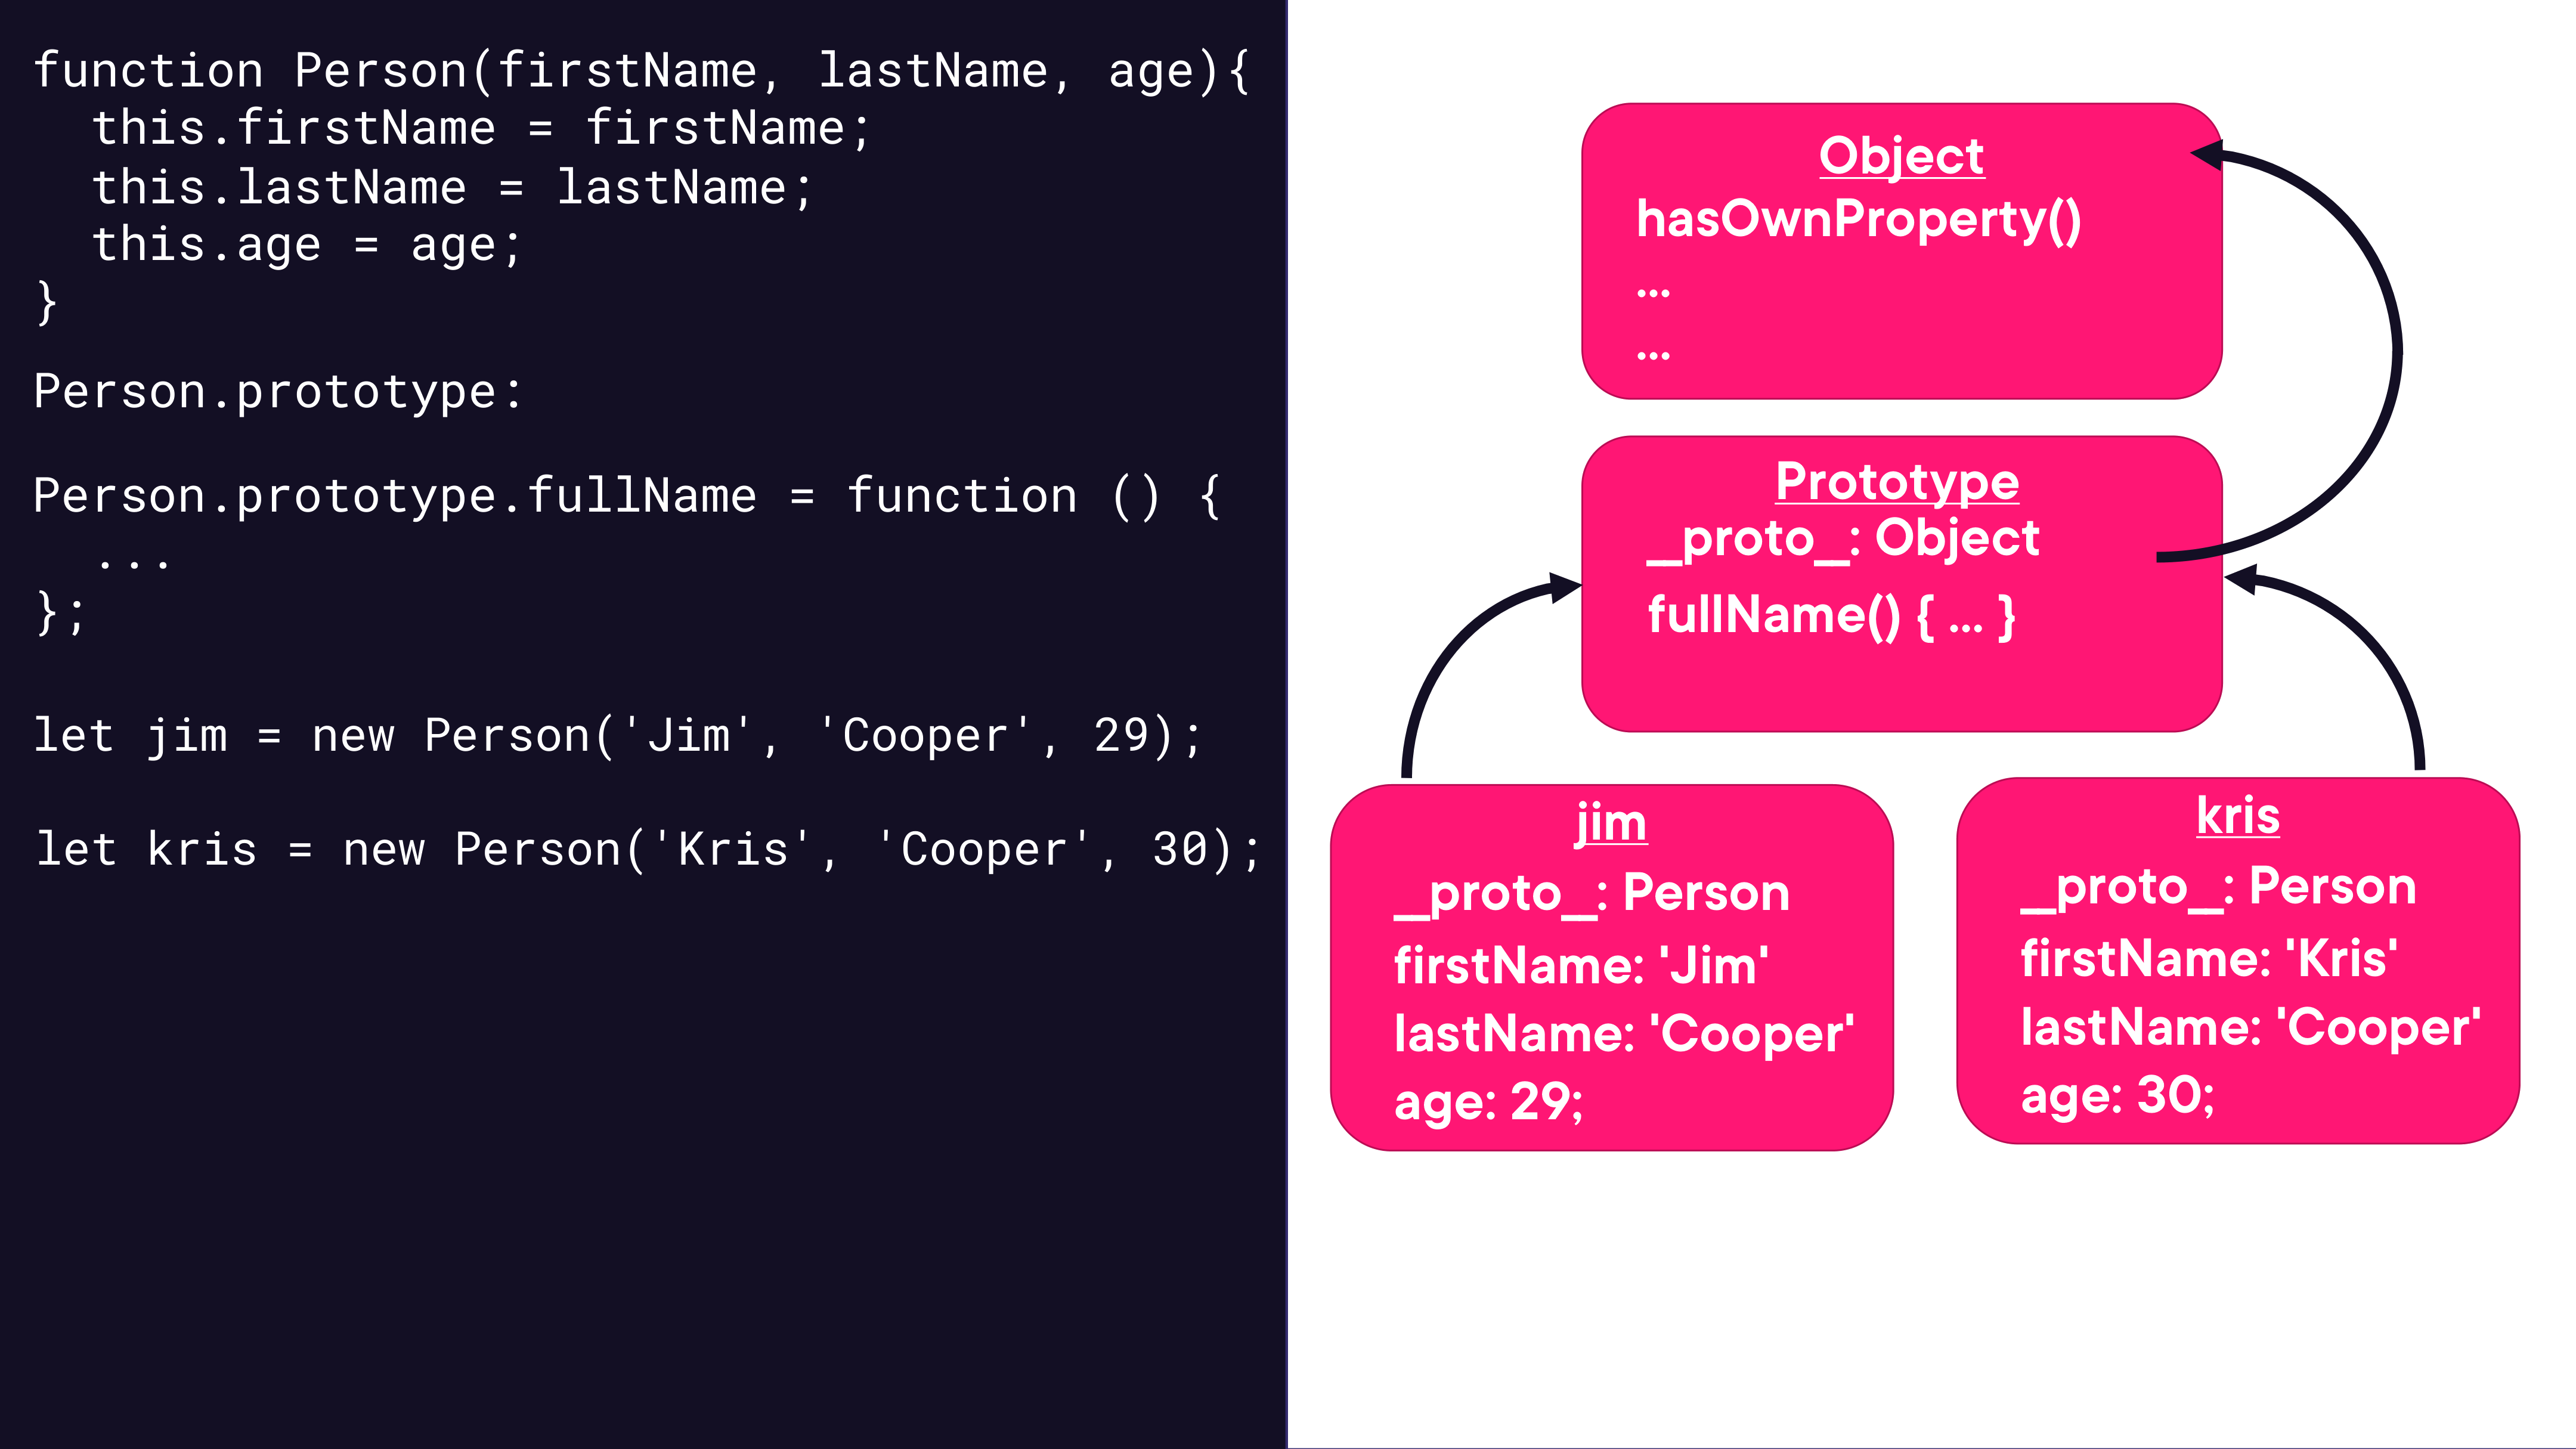

In [10]:
render_diagram(Path("assets/09-shared-prototype-two-instances.png"))

### Private State with Closures

Constructor functions can also create genuinely private state using closures — variables declared with `let` inside the constructor are not accessible from outside.

```javascript
function Person(firstName, lastName, age) {
  let adultAge = 18;           // private — not on 'this'

  this.firstName = firstName;
  this.lastName  = lastName;
  this.age       = age;

  let isAdult = () => {        // private helper
    return this.age >= adultAge;
  };

  this.isQualified = function() {  // public method using private helper
    return isAdult();
  };
}

let jim = new Person('Jim', 'Cooper', 17);
jim.isQualified();  // false
jim.adultAge;       // undefined — truly private
```

### Demo: Constructor Functions

**Building and using a constructor function with prototype methods and closure-based private state.**

See [`03-constructor-functions-demos/`](03-constructor-functions-demos/) for the full project.

The `before/script.js` starts from the prototype-based code from module 02 — the exercise is to refactor it to use a constructor function. The `after/script.js` is the completed solution shown above.

## Module 04: Inheritance with Constructor Functions and Prototypes <a id="module-04"></a>

_Shows how to wire up a full prototype-based inheritance chain between constructor functions using `Object.create()` and `Function.call()`, and how to enforce method overrides._

### Setting Up Inheritance

To make `Student` inherit from `Person` using constructor functions, three things are needed:

1. **Call the parent constructor** inside the child using `Person.call(this, ...)` to copy the parent's own properties onto the new child instance.
2. **Link the prototypes** with `Object.create(Person.prototype)` so that `Student.prototype.__proto__ === Person.prototype`.
3. **Fix `constructor`** by resetting `Student.prototype.constructor = Student` (because `Object.create` replaces it).

```javascript
function Person(firstName, lastName, age) {
  this.firstName = firstName;
  this.lastName  = lastName;
  this.age       = age;
}
Person.prototype.isAdult = function() {
  throw new Error('isAdult() must be implemented in derived constructors.');
};

function Student(firstName, lastName, age) {
  Person.call(this, firstName, lastName, age);  // inherit own properties
  this.courses = [];
}

Student.prototype = Object.create(Person.prototype);  // inherit methods
Student.prototype.constructor = Student;              // fix constructor ref

Student.prototype.enroll = function(course) {
  this.courses.push(course);
};
Student.prototype.isAdult = function() {  // override
  return this.age >= 21;
};

let jimStudent = new Student('Jim', 'Cooper', 18);
jimStudent.isAdult(); // false (18 < 21)
jimStudent.enroll({ courseId: 'CS101' });
```

### Enforcing Method Overrides

A common pattern is to define a method on the parent's prototype that throws an error, forcing every subtype to provide its own implementation. This is JavaScript's equivalent of an abstract method.

```javascript
Person.prototype.isAdult = function() {
  throw new Error('isAdult() must be implemented in derived constructors.');
};

let jimPerson = new Person('Jim', 'Cooper', 18);
// jimPerson.isAdult() → throws Error — Person is "abstract" in this sense

let jimStudent = new Student('Jim', 'Cooper', 18);
jimStudent.isAdult(); // false — uses Student's override, no error
```

### Demo: Inheritance with Constructor Functions

**Wiring up a full `Person` → `Student` inheritance chain using constructor functions.**

See [`04-inheritance-constructor-demos/`](04-inheritance-constructor-demos/) for the full project.

The `before/script.js` starts from the plain constructor function from module 03 — the exercise is to extend it with `Student`. The `after/script.js` shows the completed inheritance chain.

## Module 05: Using JavaScript Classes <a id="module-05"></a>

_Introduces the ES6 `class` syntax as a cleaner way to write the same constructor-function/prototype patterns. Covers class fields, the constructor, private fields (`#`), and private methods._

### Class Syntax

The `class` keyword is syntactic sugar over constructor functions and prototypes — it compiles to the same prototype chain underneath, but the syntax is far more readable.

When `new ClassName(...)` is called, JavaScript:
1. Creates a new empty object
2. Binds `this` to it
3. Adds the declared class fields to `this`
4. Calls the `constructor` method
5. Implicitly returns the new object


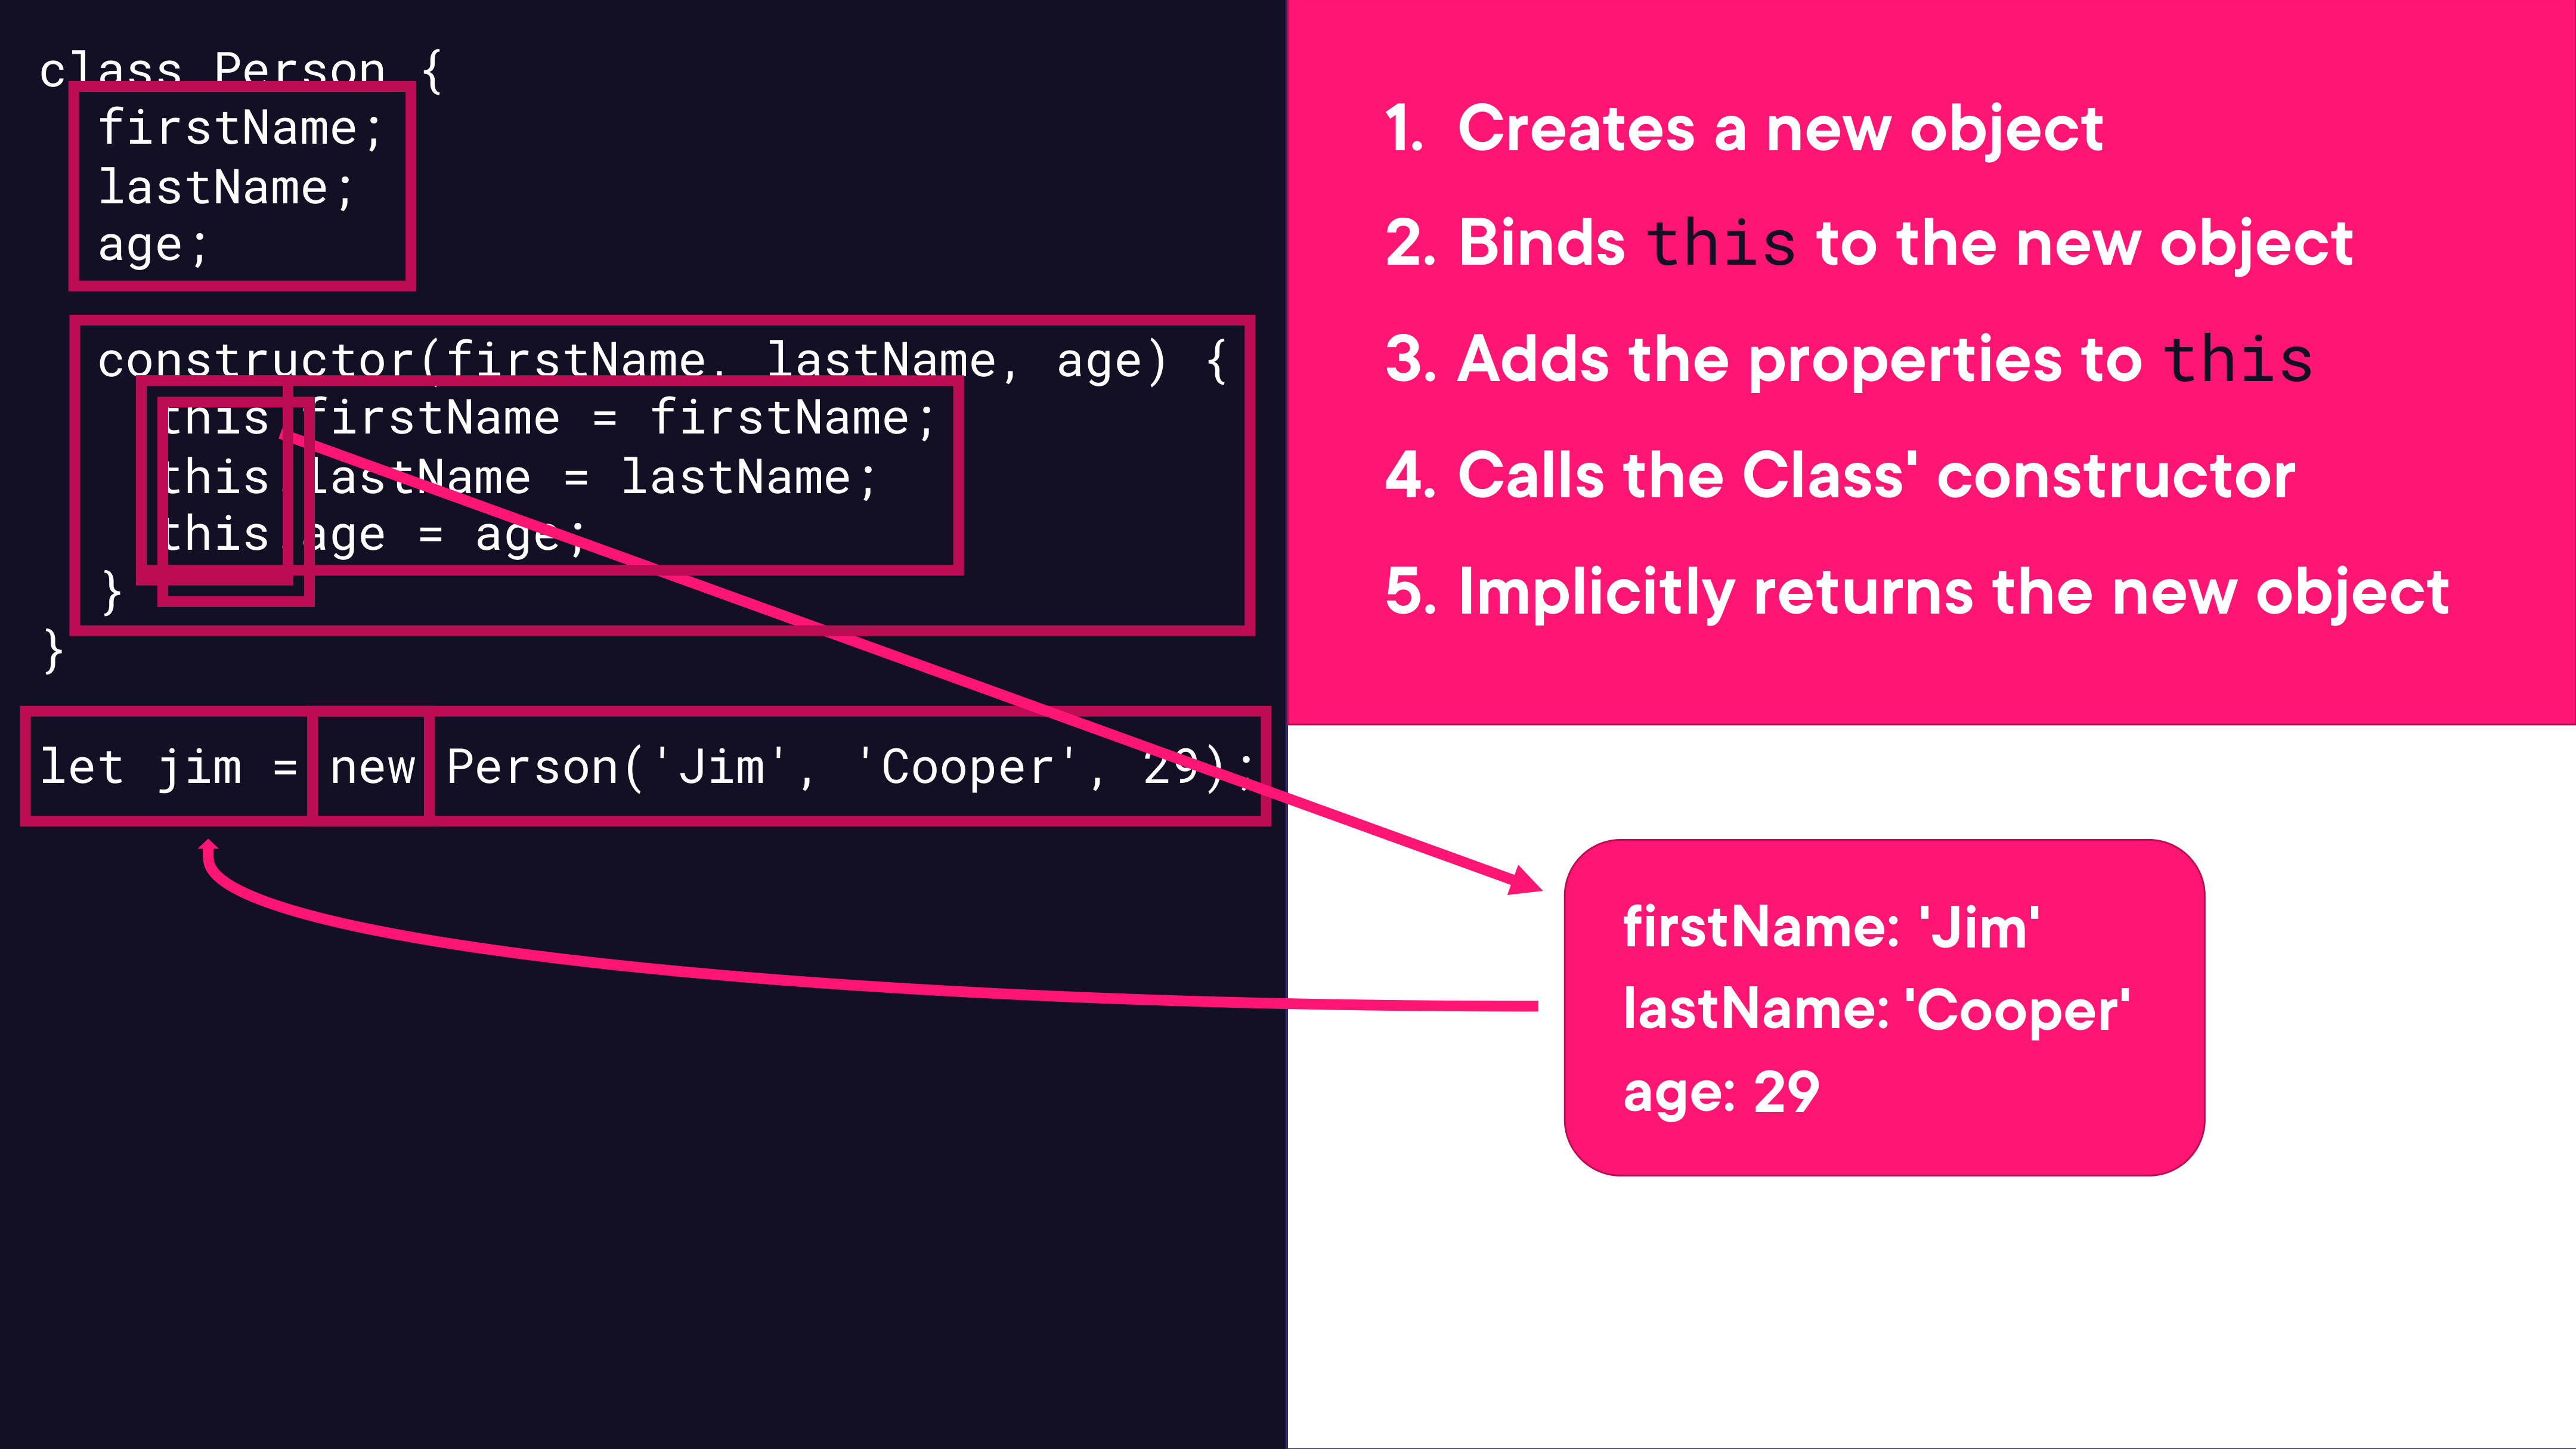

In [11]:
render_diagram(Path("assets/10-class-constructor-steps.png"))

```javascript
class Person {
  firstName;
  lastName;
  age;

  constructor(firstName, lastName, age) {
    this.firstName = firstName;
    this.lastName  = lastName;
    this.age       = age;
  }
}

let jim = new Person('Jim', 'Cooper', 29);
// jim = { firstName: 'Jim', lastName: 'Cooper', age: 29 }
```

### Private Fields and Methods

ES2022 introduced native private class fields and methods using the `#` prefix. Unlike closure-based privacy in constructor functions, private fields are enforced at the language level — accessing `jim.#adultAge` from outside the class is a syntax error.

```javascript
class Person {
  firstName;
  lastName;
  age;
  #adultAge = 18;     // private field — not accessible outside the class

  constructor(firstName, lastName, age) {
    this.firstName = firstName;
    this.lastName  = lastName;
    this.age       = age;
  }

  #isAdult() {        // private method
    return this.age >= this.#adultAge;
  }

  isQualified() {     // public method calls private method
    return this.#isAdult();
  }
}

let jim = new Person('Jim', 'Cooper', 17);
jim.isQualified();    // false
jim.#adultAge;        // SyntaxError — cannot access private field
```

### Demo: Using JavaScript Classes

**Rewriting the constructor function version as a class with private fields.**

See [`05-classes-demos/`](05-classes-demos/) for the full project.

The `before/script.js` starts from the completed inheritance chain from module 04 — the exercise is to convert it to class syntax. The `after/script.js` is the completed class version shown above.

## Module 06: Inheritance with JavaScript Classes <a id="module-06"></a>

_Covers class inheritance with `extends` and `super`, method overriding, and closes with important practical advice about when (and when not) to use class hierarchies._

### `extends` and `super`

The `extends` keyword wires up the prototype chain automatically. The child class must call `super(...)` to invoke the parent's constructor before it can access `this`.

```javascript
class Person {
  constructor(firstName, lastName, age) {
    this.firstName = firstName;
    this.lastName  = lastName;
    this.age       = age;
  }

  isAdult() {
    throw new Error('isAdult() must be implemented in derived classes.');
  }
}

class Student extends Person {
  courses = [];           // class field — initialised per instance

  enroll(course) {
    this.courses.push(course);
  }

  isAdult() {             // override
    return this.age >= 21;
  }
}

let jimPerson  = new Person('Jim', 'Cooper', 18);
let jimStudent = new Student('Jim', 'Cooper', 18);

// jimPerson.isAdult()  → throws Error (no override)
jimStudent.isAdult();   // false (18 < 21)
jimStudent.enroll({ courseId: 'CS101' });
```

### Comparing the Three Approaches

All three approaches produce the same prototype chain under the hood:

| Feature | Plain prototypes | Constructor functions | ES6 classes |
|---|---|---|---|
| Create instances | Manual `Object.setPrototypeOf` | `new FunctionName()` | `new ClassName()` |
| Shared methods | Manual on prototype object | `Fn.prototype.method = ...` | Method inside class body |
| Inheritance | `Object.setPrototypeOf(child, parent)` | `Object.create` + `Fn.call` | `extends` + `super()` |
| Private state | Not supported | Closure variables | `#field` syntax |
| Readability | Low | Medium | High |

Classes are generally preferred for new code because the syntax is cleaner and the intent is clearer.

### A Word of Warning on OO Design

Deep inheritance hierarchies can create **tight coupling** — a change to a base class ripples through every subclass in unpredictable ways. Consider **composition over inheritance** as a default: rather than `Student extends Person`, ask whether `Student` can simply hold a `person` reference and delegate to it. Inheritance is most appropriate when there is a genuine, stable "is-a" relationship between types.

### Demo: Inheritance with JavaScript Classes

**Building a complete `Person` → `Student` class hierarchy with method overrides.**

See [`06-class-inheritance-demos/`](06-class-inheritance-demos/) for the full project.

The `before/script.js` starts from the class without inheritance from module 05. The `after/script.js` adds `Student extends Person` with the `enroll()` method and `isAdult()` override shown above.